# Lab 08: Graphs, latent variables, and what the survey didn't keep

**ASTR 457, Fall 2026, posted Thu Oct 29, due Wed Nov 4 by noon (fork → PR, as always)**

This week we wrote graphs as `PyMC` code, and put a detector into the likelihood. You're going to do both, on your own midterm supernovae, on a survey that rejects everything below a threshold, and on one real Type Ia supernova observed in six bands.

Put your notebook in `submissions/<your netid>/lab08.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 35%, Part 2 30%, Part 3 25%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
import pymc as pm
import pytensor.tensor as pt
import arviz as az

NETID = 'acm18'   # <-- set this
LAB = '../../labs/08/data/'                              # from submissions/<your netid>/
MIDTERM = f'../../labs/midterm/data/{NETID}/'

g++ not available, if using conda: `conda install gxx`


## Part 1: Your midterm, as a graph (35%)

On the midterm you fit the Tripp relation to your 250 supernovae (`p2_pantheon_sne.csv` in your midterm data folder):

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10).$$

In the posted solution's 2e simulation, the 68% interval on $\beta$ contained the true $\beta$ in only **6%** of 200 fake datasets! The other four parameters covered the truth 62-66% of the time. The solution blamed attenuation. You're going to draw the graph that shows where it comes from, build the model that removes it, and check that it does.

1. Draw the probabilistic graphical model of your midterm fit (your 2b likelihood), using the same key as Day 18 - parameters you fit as blue circles, latent (unobserved) values as white circles, data as grey circles, fixed quantities as dots, and a plate over supernovae. Draw it by hand (a photo is fine) or with any drawing tool, and put the image in your notebook. Then draw the graph of how the data were actually made. Each supernova has a *true* stretch $x_{1,i}$ and a *true* color $c_i$, drawn from a population (a mean and a width for each), and the catalog's $\hat m_{B,i}$, $\hat x_{1,i}$, $\hat c_i$ are noisy measurements of the true values, with that supernova's $3\times3$ covariance $C_i$. Which arrows does the midterm's graph lack, and which circle did it shade grey that should be white?
2. Fit the second graph in `PyMC`, with latent `x1_true` and `c_true` (one per supernova, `shape=N`), a mean and a width for each population, and the three observed quantities together in a `pm.MvNormal` with each $C_i$. Add $\sigma_{\rm int}^2$ and the peculiar-velocity variance to the $m_B$ term only. Handle the contaminants as you did on the midterm, and explain how. Pick centered or non-centered by Day 19's rule (compare the measurement errors with the population widths), and justify your choice. Report the largest $\hat R$, the smallest bulk effective sample size (the latent values included) and the number of divergences, then $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 68% intervals, in a table next to your midterm values.
3. Rerun the solution's 2e simulation at your own stretches, colors and covariances, with at least 20 fake datasets and true $\beta = 2.9$ (the other true values are in the solution, which uses your catalog $x_1$ and $c$ as the true ones). Fit each with your midterm model and with the latent model, and report the mean $\hat\beta$ for each model with its standard error (the scatter over datasets divided by $\sqrt{N_{\rm sim}}$). Then explain, in a few sentences, why using the measured $x_1$ and $c$ as the regressors, with their errors only in the variance (as the midterm did), biases $\beta$ toward zero, why the latent model doesn't, and why $\beta$ is biased more than $\alpha$. Think particularly about $c$'s errors compared with the spread of $c$, and $x_1$'s errors compared with the spread of $x_1$.

#### Hints:
- You don't need to sample each fake dataset in 1.3. Everything here is Gaussian, so you can integrate the true $x_1$ and $c$ out on paper - each supernova's observed $(\hat m_B, \hat x_1, \hat c)$ is then Gaussian, with a mean and covariance that depend only on the parameters and the two populations. Write them down, maximize that likelihood, and check its answer on your real data against your `PyMC` fit.
- **Don't use `pm.find_MAP` on the 1.2 model.** Its peak over all the latent values at once is degenerate (the population width collapses), and you'll get a wrong $\beta$ that looks reasonable.

In [2]:
# Part 1: your work here
from astropy.cosmology import FlatLambdaCDM

NETID = 'acm18'   # <-- set this
DATA = f'mdata/acm18/'   # from submissions/<your netid>/

def load(name):
    """Read one of your CSV files as a pandas table; d['column'].to_numpy() gives a numpy array. Names stay strings."""
    return pd.read_csv(DATA + name + '.csv', dtype={'name': str})

p2 = load('p2_pantheon_sne')

z = p2['z'].to_numpy()
mB = p2['mB'].to_numpy()
x1 = p2['x1'].to_numpy()
color = p2['c'].to_numpy()
host_logmass = p2['host_logmass'].to_numpy()

cosmo = FlatLambdaCDM(H0=70,Om0=0.3)
mu = cosmo.distmod(z).value
hubble_resid = mB-mu

c_kms = 299792.458
sigma_mu_pec = (5/np.log(10))*(250/(c_kms*z))

#start the Cleaning Process
p2_all = p2.copy().reset_index(drop=True)

z = p2_all['z'].to_numpy()
mB = p2_all['mB'].to_numpy()
x1 = p2_all['x1'].to_numpy()
color = p2_all['c'].to_numpy()
host_logmass = p2_all['host_logmass'].to_numpy()
high_mass = (host_logmass>=10).astype(float)

cosmo = FlatLambdaCDM(H0=70,Om0=0.3)
mu = cosmo.distmod(z).value

# mB-mu = M_B-alpha*x1+beta*c+gamma*high_mass
y = mB-mu
X = np.column_stack((np.ones(len(p2_all)),-x1,color,high_mass))

theta = np.linalg.lstsq(X,y,rcond=None)[0]
model = X@theta
resid = y-model

n,k = X.shape
s2 = resid@resid/(n-k)
leverage = np.sum(X*(X@np.linalg.inv(X.T@X)),axis=1)
studentized_resid = resid/np.sqrt(s2*(1-leverage))

cut = 4.0
contaminant = np.abs(studentized_resid)>cut
p2_clean = p2_all.loc[~contaminant].copy().reset_index(drop=True)

flagged = p2_all.loc[contaminant,['name','z','mB','x1','c','host_logmass']].copy()
flagged['resid_mag'] = resid[contaminant]
flagged['studentized_resid'] = studentized_resid[contaminant]
flagged['abs_studentized_resid'] = np.abs(studentized_resid[contaminant])
flagged = flagged.sort_values('abs_studentized_resid',ascending=False)

p2 = p2_clean.copy()

z = p2['z'].to_numpy()

mB = p2['mB'].to_numpy()
x1 = p2['x1'].to_numpy()
color = p2['c'].to_numpy()
host_logmass = p2['host_logmass'].to_numpy()

mu = cosmo.distmod(z).value

sigma_mu_pec = (5/np.log(10))*(250/(c_kms*z))

To remove the contaminants I flagged sources with extreemly large residuals. Looking at the residual plot it is pretty clear how these sources do not fit with the rets of the data. I am removing these outliers from the data frame and then continuing onwards with the cleaned dataset. 

In [3]:
# Part 1.2: hierarchical Tripp model

N = len(p2)

# Rebuild quantities that must match the cleaned dataframe
high_mass = (host_logmass >= 10).astype(float)
obs = np.column_stack((mB, x1, color))

# Catalog covariance of (mB, x1, c) for each supernova
C = np.zeros((N,3,3))

C[:,0,0] = p2['mB_err'].to_numpy()**2
C[:,1,1] = p2['x1_err'].to_numpy()**2
C[:,2,2] = p2['c_err'].to_numpy()**2

C[:,0,1] = C[:,1,0] = p2['cov_mB_x1'].to_numpy()
C[:,0,2] = C[:,2,0] = p2['cov_mB_c'].to_numpy()
C[:,1,2] = C[:,2,1] = p2['cov_x1_c'].to_numpy()

print('N =',N)
print('observed shape =',obs.shape)
print('covariance shape =',C.shape)

N = 247
observed shape = (247, 3)
covariance shape = (247, 3, 3)


In [4]:
x1_ratio = np.median(p2['x1_err'])/np.std(x1,ddof=1)
c_ratio = np.median(p2['c_err'])/np.std(color,ddof=1)

print('median x1 error / x1 width = {:.3f}'.format(x1_ratio))
print('median c error / c width = {:.3f}'.format(c_ratio))

median x1 error / x1 width = 0.166
median c error / c width = 0.362


Given that both of these ratios are $<1$ I am deciding to use a centered model. Day 19 tells us that a centered model works best when the measurment errors are small when compared to the spread of the data, this is the current case.

In [5]:
with pm.Model() as latent_model:

    # Tripp relation parameters
    M = pm.Uniform('M',-20.5,-18.0)
    alpha = pm.Uniform('alpha',0.0,0.5)
    beta = pm.Uniform('beta',0.0,6.0)
    gamma = pm.Uniform('gamma',-0.5,0.5)
    sigma_int = pm.Uniform('sigma_int',0.001,0.5)

    # Population parameters
    mu_x1 = pm.Normal('mu_x1',0.0,2.0)
    sigma_x1 = pm.HalfNormal('sigma_x1',2.0)

    mu_c = pm.Normal('mu_c',0.0,0.2)
    sigma_c = pm.HalfNormal('sigma_c',0.2)

    # Latent true stretch and color
    x1_true = pm.Normal('x1_true',mu_x1,sigma_x1,shape=N)
    c_true = pm.Normal('c_true',mu_c,sigma_c,shape=N)

    # Latent true magnitude from the Tripp relation
    mB_true = pm.Deterministic('mB_true',M+mu-alpha*x1_true+beta*c_true+gamma*high_mass)

    # Mean of observed (mB,x1,c)
    obs_true = pt.stack((mB_true,x1_true,c_true),axis=1)

    # Add sigma_int and sigma_mu_pec only to mB variance
    cov = pt.as_tensor_variable(C)
    cov = pt.set_subtensor(cov[:,0,0],cov[:,0,0]+sigma_int**2+sigma_mu_pec**2)

    # Joint light-curve measurement
    likelihood = pm.MvNormal('likelihood',mu=obs_true,cov=cov,observed=obs)

    trace = pm.sample(2000,tune=2000,chains=4,cores=1,target_accept=0.9,random_seed=457,return_inferencedata=True)

Initializing NUTS using jitter+adapt_diag...
C:\Users\austi\anaconda3\envs\astr457\Lib\site-packages\pytensor\tensor\rewriting\elemwise.py:1039: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(
Sequential sampling (4 chains in 1 job)
NUTS: [M, alpha, beta, gamma, sigma_int, mu_x1, sigma_x1, mu_c, sigma_c, x1_true, c_true]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 285 seconds.


In [6]:
summary = az.summary(
    trace,
    var_names=[
        'M','alpha','beta','gamma','sigma_int',
        'mu_x1','sigma_x1','mu_c','sigma_c',
        'x1_true','c_true'
    ]
)

largest_rhat = summary['r_hat'].max()
smallest_ess = summary['ess_bulk'].min()
divergences = int(trace.sample_stats['diverging'].sum())

print('largest R-hat = {:.3f}'.format(largest_rhat))
print('smallest bulk ESS = {:.0f}'.format(smallest_ess))
print('divergences = {}'.format(divergences))

largest R-hat = 1.003
smallest bulk ESS = 4204
divergences = 0


In [7]:
def posterior_result(samples):
    q = np.percentile(samples,[16,50,84])
    return q[1],q[1]-q[0],q[2]-q[1]

parameters = ['alpha','beta','gamma','sigma_int']

# Extract directly from the latest latent-model trace
latent = {
    p: posterior_result(trace.posterior[p].values.ravel())
    for p in parameters
}

midterm = {
    'alpha': (0.14,0.01,0.01),
    'beta': (2.90,0.10,0.10),
    'gamma': (-0.04,0.02,0.02),
    'sigma_int': (0.11,0.01,0.01)
}

def fmt(v):
    med,minus,plus = v
    return r'${:.3f}^{{+{:.3f}}}_{{-{:.3f}}}$'.format(
        med,plus,minus
    )

comparison = pd.DataFrame({
    'midterm': [fmt(midterm[p]) for p in parameters],
    'latent model': [fmt(latent[p]) for p in parameters]
},index=parameters)

comparison.index.name = 'parameter'
comparison



,midterm,latent model
parameter,,
alpha,$0.140^{+0.010}_{-0.010}$,$0.152^{+0.010}_{-0.010}$
beta,$2.900^{+0.100}_{-0.100}$,$3.180^{+0.120}_{-0.122}$
gamma,$-0.040^{+0.020}_{-0.020}$,$-0.043^{+0.019}_{-0.018}$
sigma_int,$0.110^{+0.010}_{-0.010}$,$0.106^{+0.009}_{-0.009}$


true beta = 2.90
failed simulations = []


,model,mean_beta,standard_error,bias,N_sim
0,midterm,2.678321,0.014272,-0.221679,30
1,latent,2.882634,0.016919,-0.017366,30


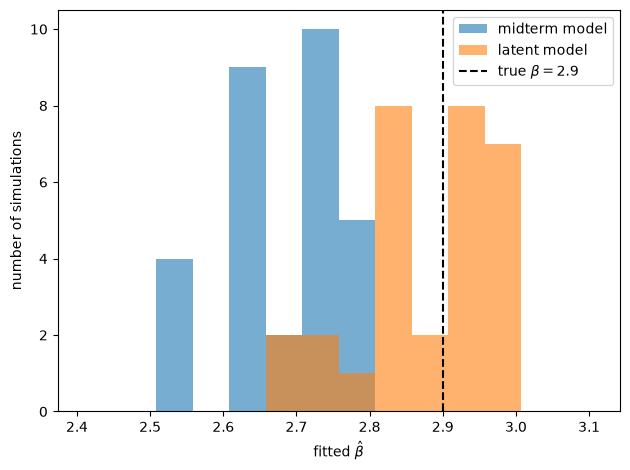

In [8]:
# Part 1.3: attenuation simulation, midterm model vs latent model

N = len(p2)
high_mass = (host_logmass >= 10).astype(float)

# SALT2 covariance matrices for measured (mB,x1,c)
C = np.zeros((N,3,3))
C[:,0,0] = p2['mB_err'].to_numpy()**2
C[:,1,1] = p2['x1_err'].to_numpy()**2
C[:,2,2] = p2['c_err'].to_numpy()**2
C[:,0,1] = C[:,1,0] = p2['cov_mB_x1'].to_numpy()
C[:,0,2] = C[:,2,0] = p2['cov_mB_c'].to_numpy()
C[:,1,2] = C[:,2,1] = p2['cov_x1_c'].to_numpy()
L = np.linalg.cholesky(C)

# p = (M,alpha,beta,gamma,log_sigma_int)
def nll_midterm(p,d):
    M,alpha,beta,gamma,log_sigma_int = p
    sigma_int = np.exp(log_sigma_int)
    model = M+d['mu']-alpha*d['x1']+beta*d['c']+gamma*d['high_mass']
    v = np.array([1.0,alpha,-beta])
    var = (np.einsum('j,njk,k->n',v,d['C'],v)
           +d['sigma_mu_pec']**2+sigma_int**2)
    resid = d['mB']-model
    if np.any(var <= 0) or np.any(~np.isfinite(var)):
        return np.inf
    return 0.5*np.sum(resid**2/var+np.log(var)+np.log(2*np.pi))

# p = (M,alpha,beta,gamma,log_sigma_int,
#      mu_x1,log_sigma_x1,mu_c,log_sigma_c)
def nll_latent(p,d):
    M,alpha,beta,gamma,log_sigma_int = p[:5]
    mu_x1,log_sigma_x1,mu_c,log_sigma_c = p[5:]
    sigma_int = np.exp(log_sigma_int)
    sigma_x1 = np.exp(log_sigma_x1)
    sigma_c = np.exp(log_sigma_c)

    mean = np.column_stack((
        M+d['mu']-alpha*mu_x1+beta*mu_c+gamma*d['high_mass'],
        np.full(d['N'],mu_x1),
        np.full(d['N'],mu_c)
    ))

    # Population covariance after integrating out true x1 and c
    A = np.array([[-alpha,beta],[1.0,0.0],[0.0,1.0]])
    pop_cov = A@np.diag([sigma_x1**2,sigma_c**2])@A.T
    cov = d['C']+pop_cov[None,:,:]
    cov[:,0,0] += sigma_int**2+d['sigma_mu_pec']**2

    resid = d['obs']-mean
    sign,logdet = np.linalg.slogdet(cov)
    if np.any(sign <= 0) or np.any(~np.isfinite(logdet)):
        return np.inf

    quad = np.einsum('ni,nij,nj->n',resid,np.linalg.inv(cov),resid)
    return 0.5*np.sum(quad+logdet+3*np.log(2*np.pi))

# True simulation parameters; catalog x1 and c are treated as true values
truth = np.array([-19.30,0.14,2.90,-0.06,np.log(0.11)])
x1_true = x1.copy()
c_true = color.copy()

p0_midterm = truth.copy()
p0_latent = np.r_[
    truth,
    np.mean(x1_true),np.log(np.std(x1_true,ddof=1)),
    np.mean(c_true),np.log(np.std(c_true,ddof=1))
]

bounds_midterm = [
    (-20.5,-18.0),(0.0,0.5),(0.0,6.0),(-0.5,0.5),
    (np.log(0.001),np.log(0.5))
]

bounds_latent = bounds_midterm+[
    (-4.0,4.0),(np.log(0.01),np.log(5.0)),
    (-0.5,0.5),(np.log(0.001),np.log(1.0))
]

rng = np.random.default_rng(2026)
nsim = 30
beta_midterm,beta_latent,failed = [],[],[]

for isim in range(nsim):

    # Correlated measurement errors in mB, x1 and c
    e = np.einsum('nij,nj->ni',L,rng.standard_normal((N,3)))

    # True magnitudes use true x1 and c
    mB_true = (truth[0]+mu-truth[1]*x1_true
               +truth[2]*c_true+truth[3]*high_mass)

    # Catalog contains noisy measured x1, c and mB
    x1_sim = x1_true+e[:,1]
    c_sim = c_true+e[:,2]
    mB_sim = (mB_true+e[:,0]
              +np.exp(truth[4])*rng.standard_normal(N)
              +sigma_mu_pec*rng.standard_normal(N))

    d = dict(
        N=N,mu=mu,high_mass=high_mass,
        sigma_mu_pec=sigma_mu_pec,C=C,
        mB=mB_sim,x1=x1_sim,c=c_sim,
        obs=np.column_stack((mB_sim,x1_sim,c_sim))
    )

    fm = minimize(
        nll_midterm,p0_midterm,args=(d,),
        method='L-BFGS-B',bounds=bounds_midterm
    )

    fl = minimize(
        nll_latent,p0_latent,args=(d,),
        method='L-BFGS-B',bounds=bounds_latent
    )

    if fm.success and fl.success:
        beta_midterm.append(fm.x[2])
        beta_latent.append(fl.x[2])
    else:
        failed.append(isim)

beta_midterm = np.asarray(beta_midterm)
beta_latent = np.asarray(beta_latent)

def mean_se(v):
    return np.mean(v),np.std(v,ddof=1)/np.sqrt(len(v))

mid_mean,mid_se = mean_se(beta_midterm)
lat_mean,lat_se = mean_se(beta_latent)

results = pd.DataFrame({
    'model':['midterm','latent'],
    'mean_beta':[mid_mean,lat_mean],
    'standard_error':[mid_se,lat_se],
    'bias':[mid_mean-truth[2],lat_mean-truth[2]],
    'N_sim':[len(beta_midterm),len(beta_latent)]
})

print('true beta = {:.2f}'.format(truth[2]))
print('failed simulations =',failed)
display(results)

bins = np.linspace(
    min(beta_midterm.min(),beta_latent.min())-0.1,
    max(beta_midterm.max(),beta_latent.max())+0.1,15
)

plt.hist(beta_midterm,bins=bins,alpha=0.6,label='midterm model')
plt.hist(beta_latent,bins=bins,alpha=0.6,label='latent model')
plt.axvline(truth[2],color='k',ls='--',label=r'true $\beta=2.9$')
plt.xlabel(r'fitted $\hat{\beta}$')
plt.ylabel('number of simulations')
plt.legend()
plt.tight_layout()
plt.show()

assert len(beta_midterm) >= 20
assert len(beta_midterm) == len(beta_latent)
assert np.all(np.isfinite(beta_midterm))
assert np.all(np.isfinite(beta_latent))


**ANSWER (the two graphs, the table, the simulation result, then the explanation):**

### Midterm Fit:

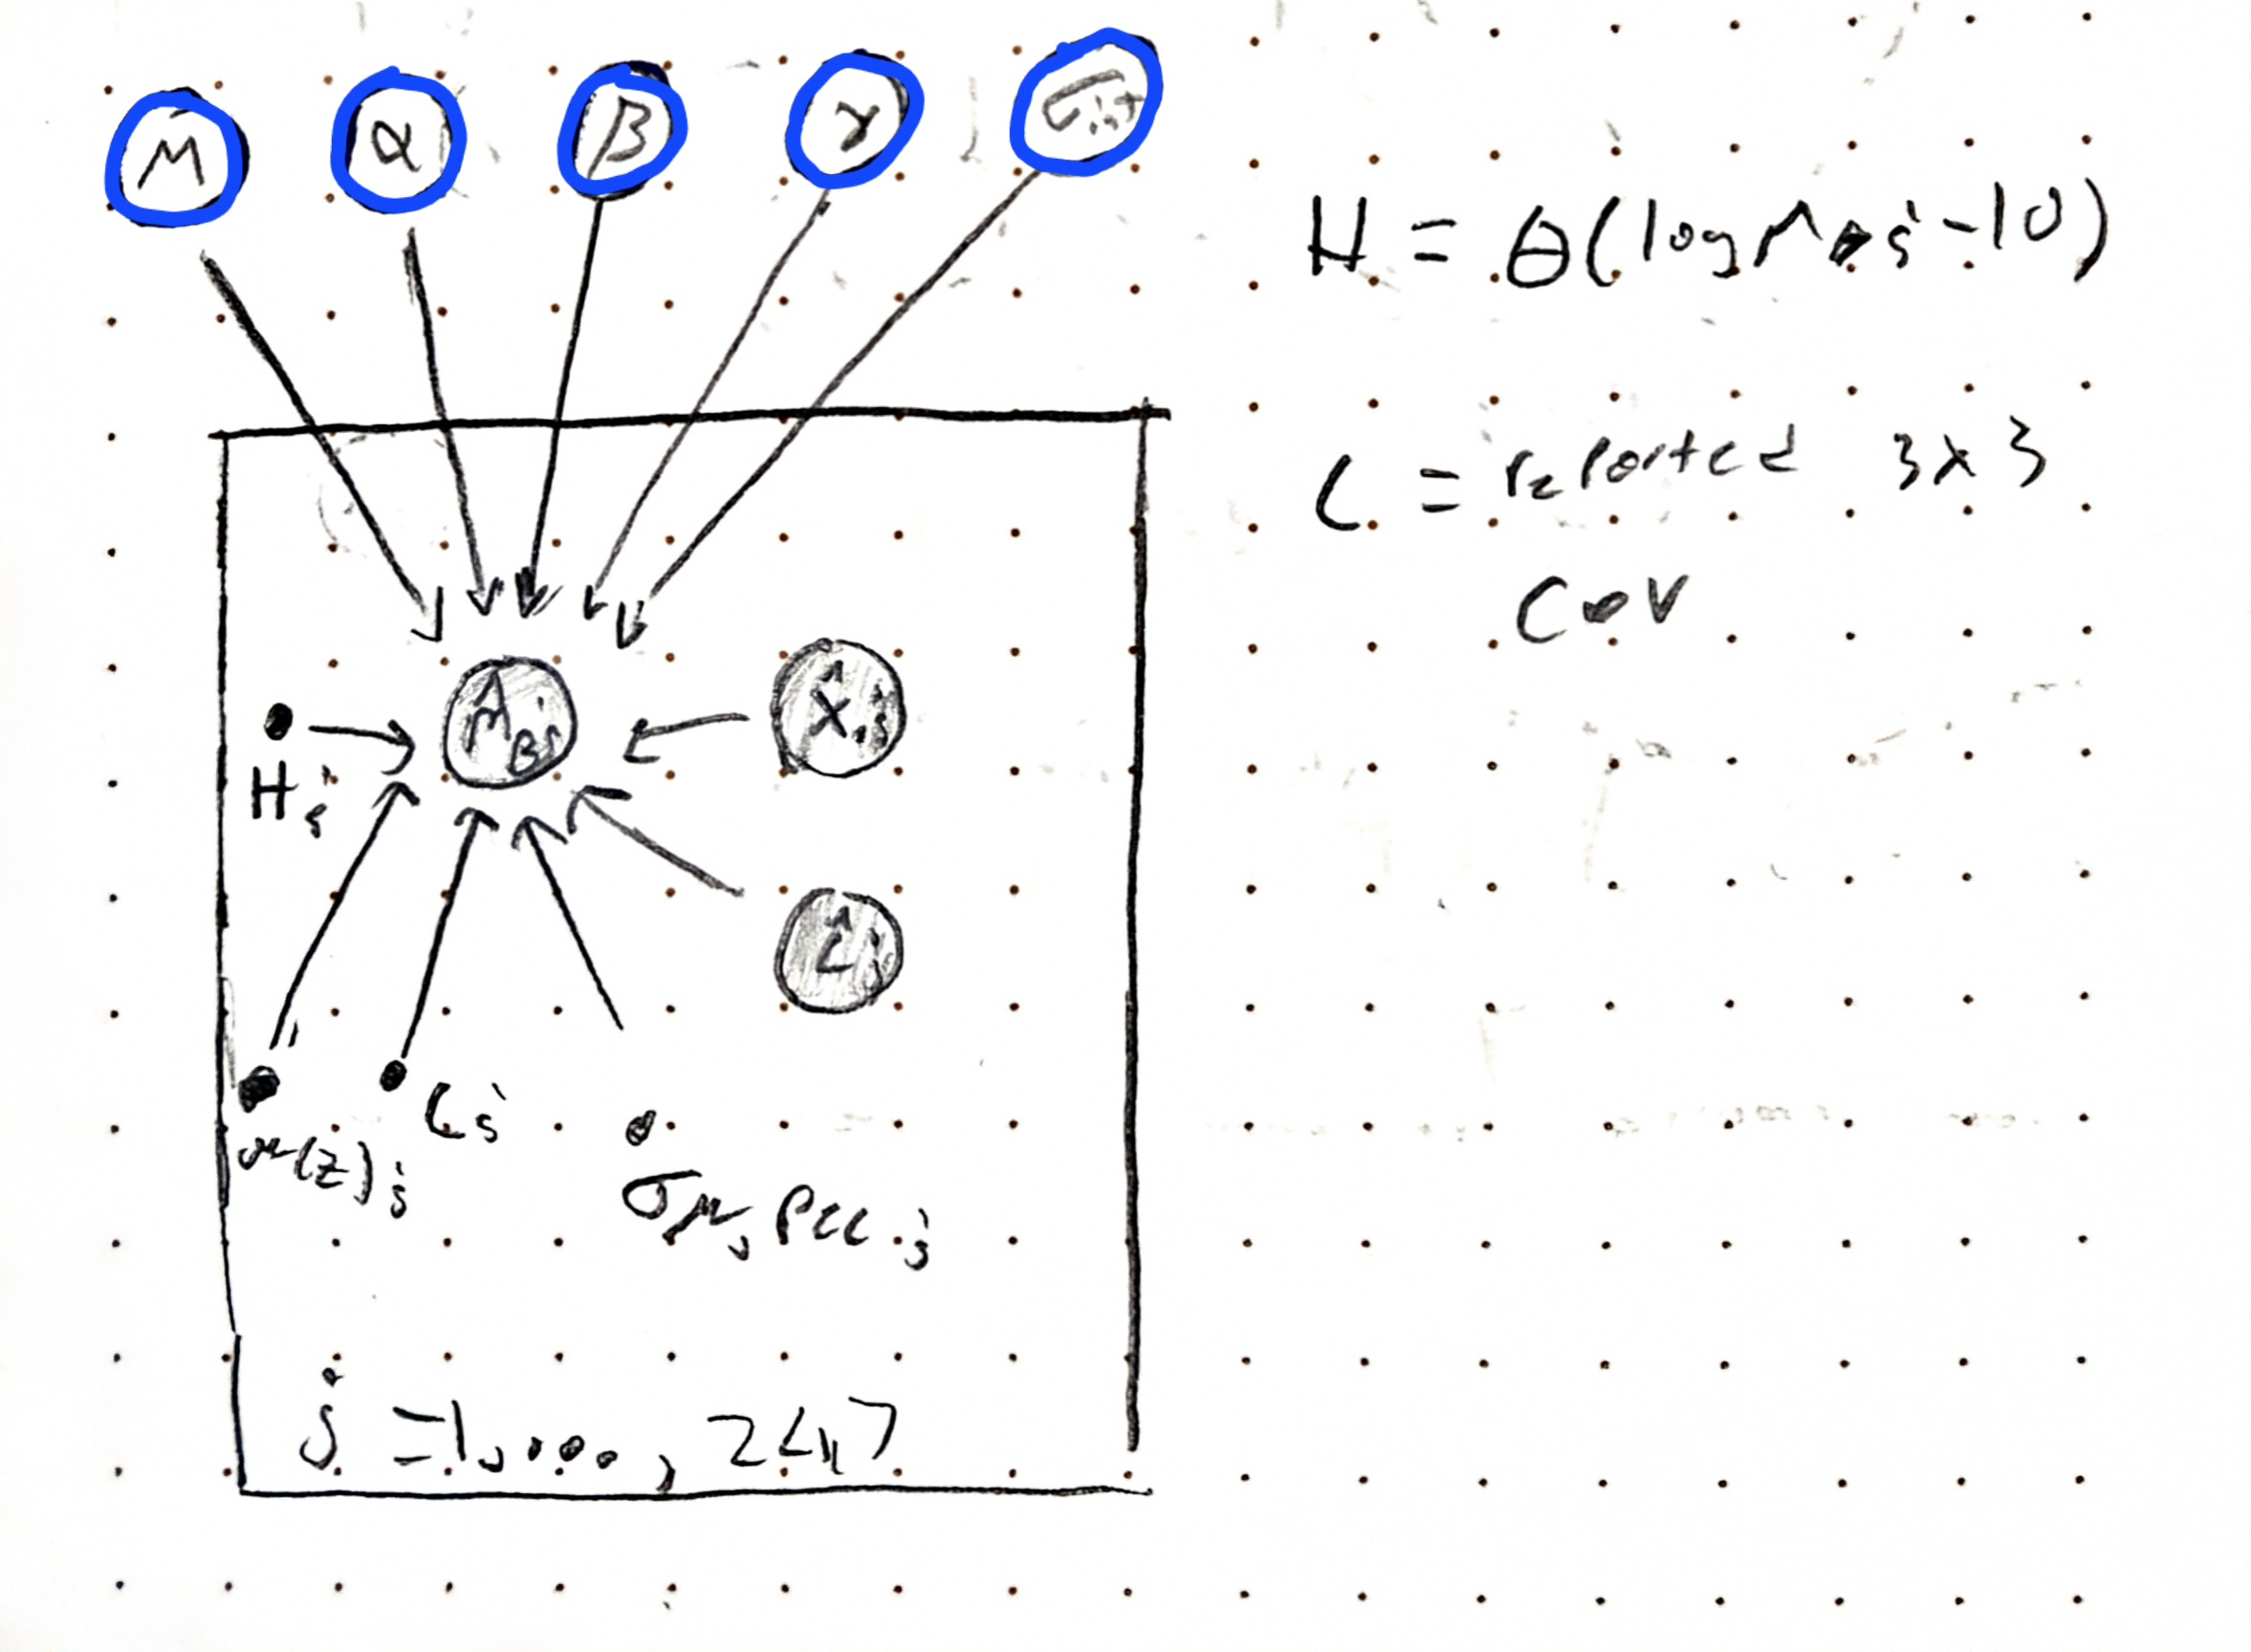

This midterm fit shades m_B grey when it should actually be treated as a latenet parameter that determines the measured value which has some scatter applied to it according to sig_perc and the 3x3 cov matrix. The model also treats X1 and Ci as true values but they should also be pulled from some scatter determined outside the interating block, they should also be white and their outputs after considering scatter should be the measured variables. 

### How The Midterm data was Actaully Made

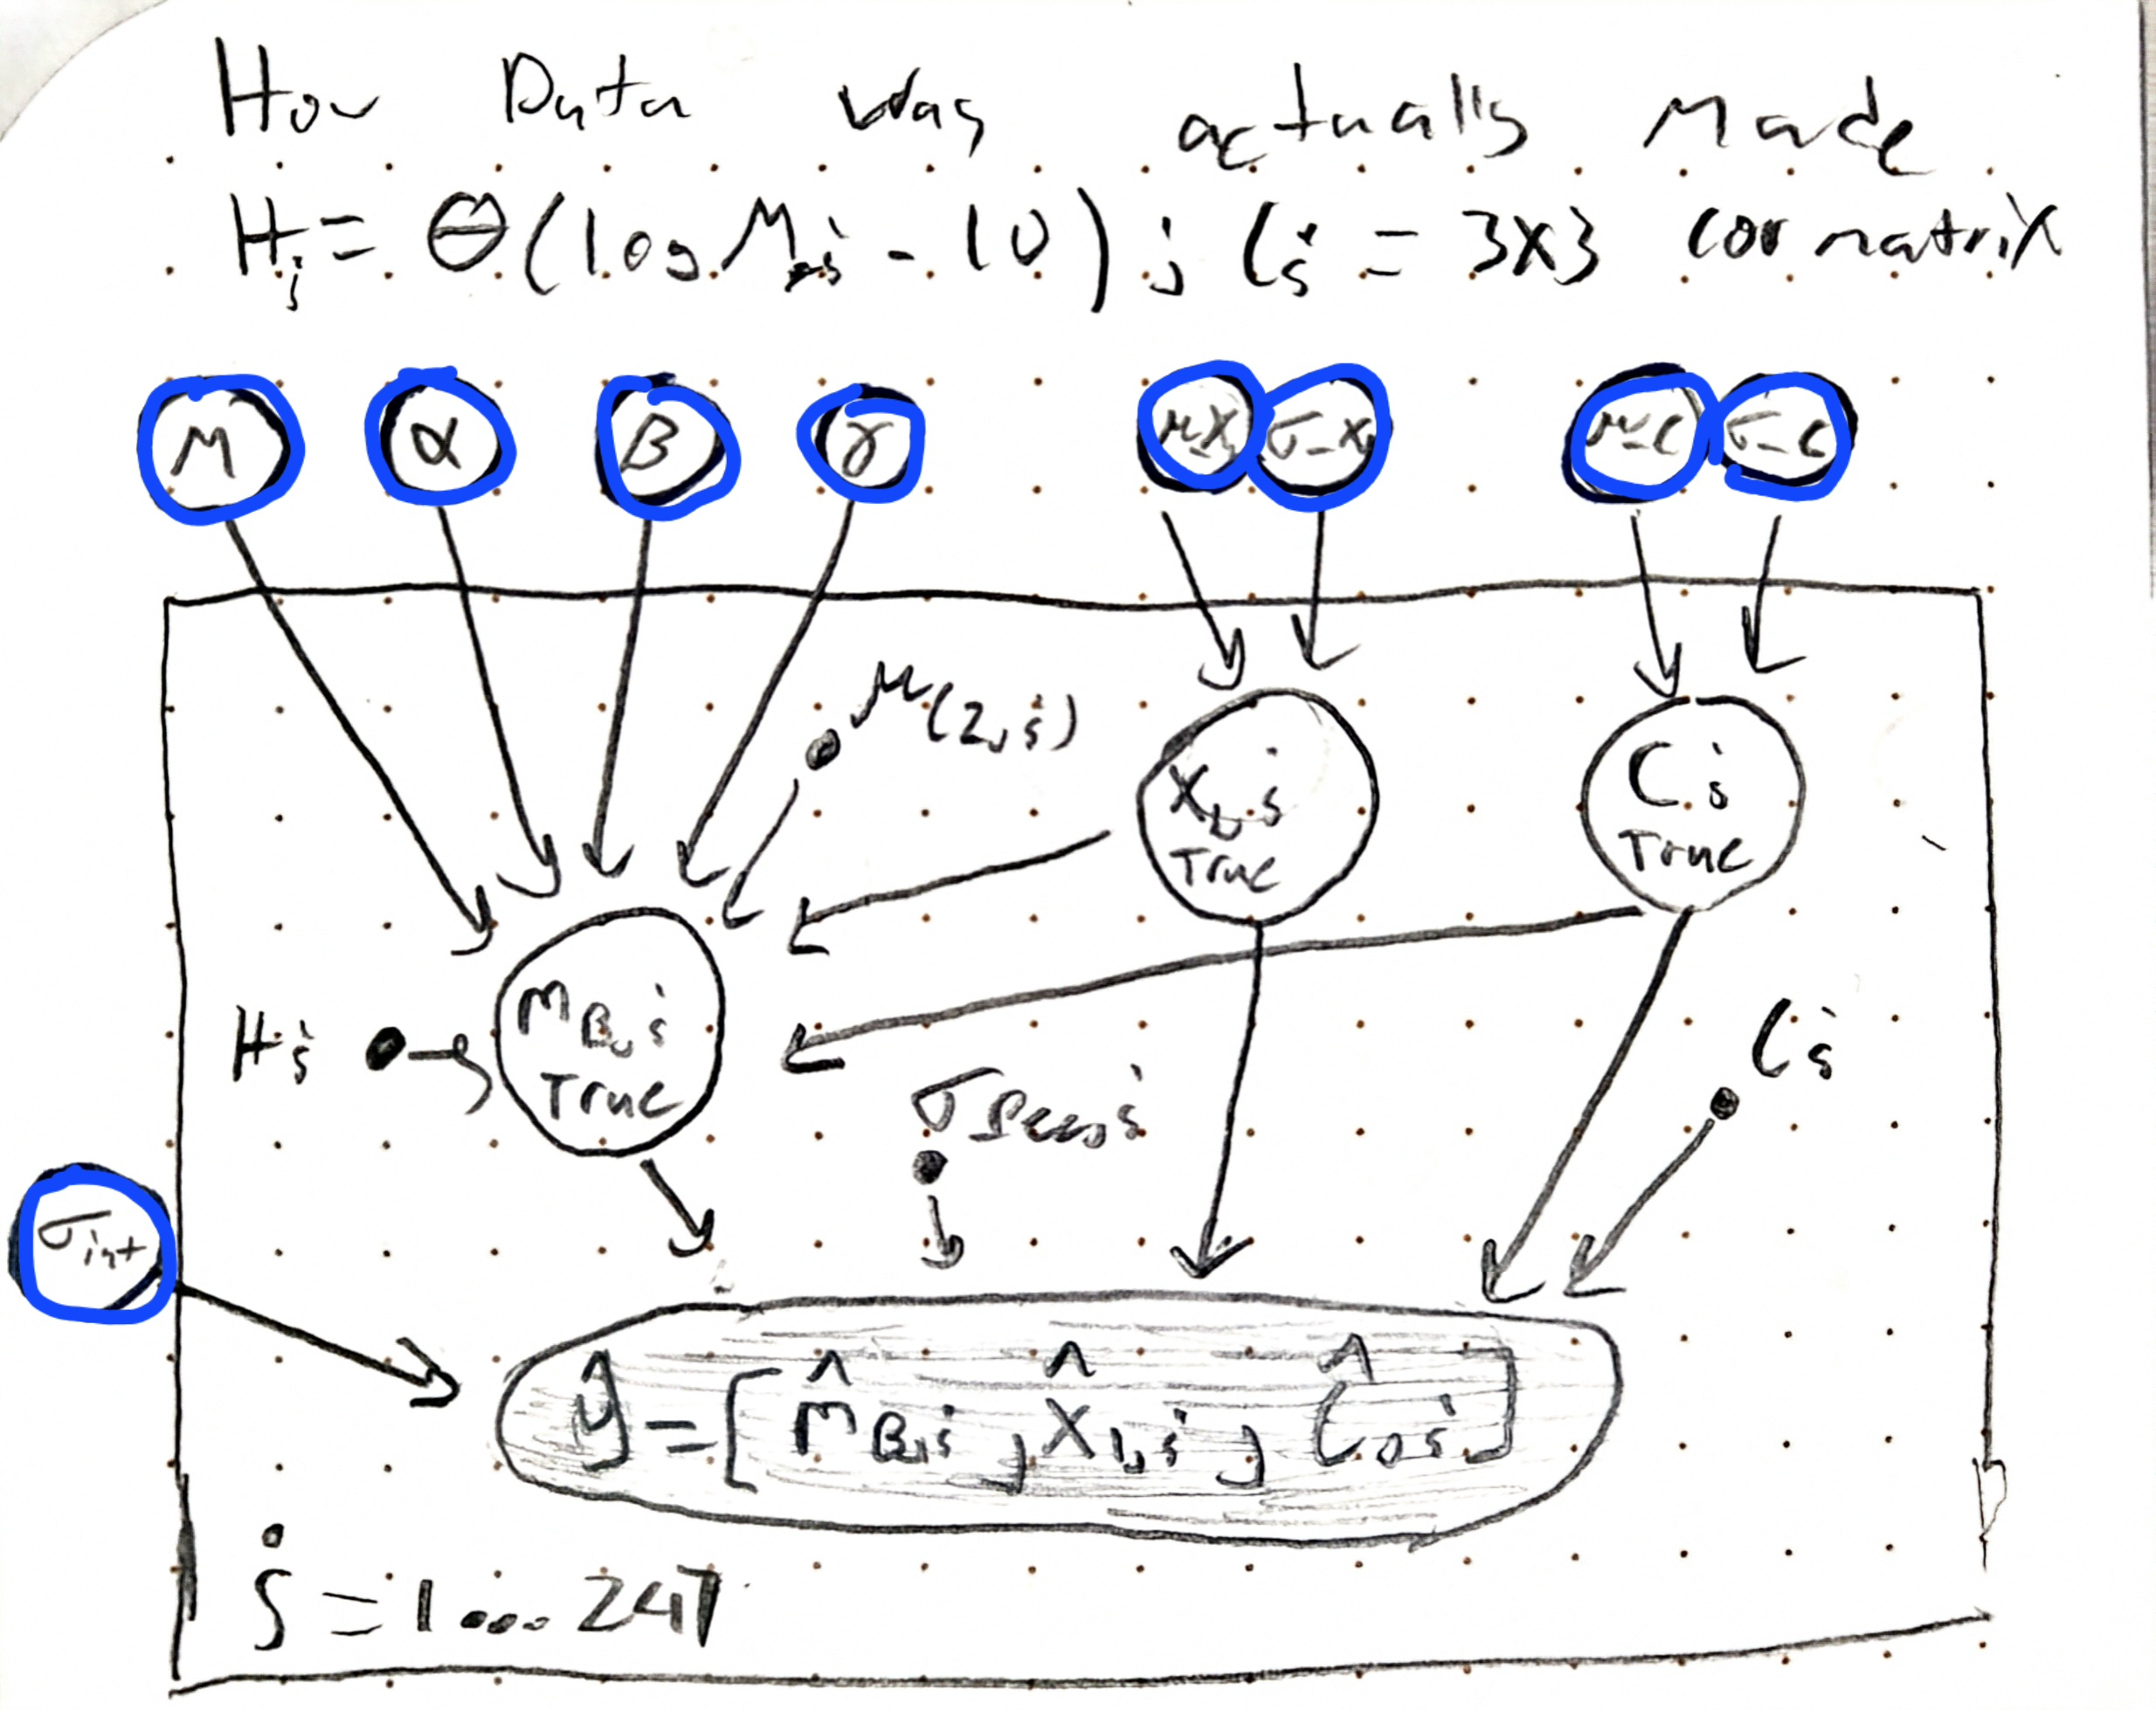

### Simulation Explanation

My midterm treated the noisy measurments of $x_1$ and $c$ as exact predictors. This treatment does not account for the apparent spread of the parameters without creating a corresponding change in apperent magnitude. This spreas in $x_1$ and $c$ lowers the slope of the fitted line $\beta$. That is why the model from the midterm is biase toward 0. 

The latent model accounts for these errors by seperating the true values of $x_1$ and $c$ from the noisy catalouge values. By accounting for the measurment error it keeps this extra spread from effecting the latent $m_B$true values removing this attenuation. The bias is stronger for $\beta$ because the color errors are larger relative to the population spread, 0.362, that the stretch errors relative to their population spread, 0.166. $\beta$ is assigned to the color term while $\alpha$ is assigned to stretch.

## Part 2: What the survey didn't keep (30%)

We'll use a simplified model of photon-counting aperture photometry. A source with true flux $F$ (in units of a reference flux $F_0$) gives, on average, $\epsilon F + \nu$ counts - $\epsilon = 226.27$ counts per $F_0$ is the exposure, and $\nu = 9.373$ counts is the background (sky plus detector) that lands in the aperture with or without a source. The survey keeps a source only if it counts $n > 32$ photons (about a 4$\sigma$ detection) - anything fainter never makes it into the catalog.

The true fluxes come from a **lognormal** population, $\ln F \sim \mathcal{N}(\mu, \sigma)$. Your catalog, `08/data/<your netid>.csv`, has one column, `n_counts`, for the first 1500 sources the survey detected. I generated it, so I know your $\mu$ and $\sigma$, and how many sources the survey missed. Your $\mu$ and $\sigma$ are graded by how far they are from the truth in units of your own error bars.

1. Histogram your counts (a log axis in $n$ helps). The paragraph above is how the survey was designed to work - your file is what it actually did. If you find something the paragraph doesn't describe, you'll have to deal with it, and there is more than one legitimate way to account for it. Reread Day 19's slides on what a survey doesn't keep before you decide. Make a call, and defend it. Explain what you found and how many sources it affects, what you did about it and why you chose that over the alternatives, and what it does to $\mu$ and $\sigma$ (show it - fit with and without your fix). Carry your choice through every fit below.
2. Write the sampling distribution of $n$ given $F$. Write the detection probability $p_{\rm det}(F) = P(n > 32 \mid F)$ in closed form using `scipy.special.gammainc` (the regularized lower incomplete gamma function - **be careful** whether the threshold is 32 or 33), and check it against `scipy.stats.poisson.sf` at a few fluxes. Plot $p_{\rm det}$ against $F$ on a log axis. At what flux is a source detected half the time?
3. Draw the graph for this survey, with the detection step in it (the selection graph from class is the model). Which nodes are latent, which are data, which are fixed, and where do $N$ and $N_{\rm det}$ go?
4. For a source that 2.1 doesn't affect, the naive likelihood of its count, with its true flux integrated out, is
$$p(n_i \mid \mu, \sigma) = \int \mathrm{Poisson}(n_i \mid \epsilon F + \nu)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F.$$
Do that integral on a grid in $\ln F$, and find the $(\mu, \sigma)$ that maximizes the product over your 1500 sources. Then add the detector by subtracting $N_{\rm det} \ln f_{\rm det}(\mu, \sigma)$ from the log-likelihood, with $f_{\rm det} = \int p_{\rm det}(F)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F$ the fraction of the population that the survey detects, and fit again. Report $(\mu, \sigma)$ for both fits with uncertainties (curvature, a grid of the posterior, or `PyMC` with `pm.Potential` - your choice, but state which). What is $f_{\rm det}$, and so about how many sources did your survey miss?
5. Histogram $\ln \hat F$, with $\hat F = (n - \nu)/\epsilon$. On it, draw the naive population (scaled to your 1500 sources) and the corrected population (scaled to the $N_{\rm det}/f_{\rm det}$ sources it says were there). Then simulate your survey from the corrected fit - sample that many true fluxes, sample a Poisson count for each, put the counts through your detector as it actually ran (2.1), keep the ones with $n > 32$, and plot the histogram of their $\ln \hat F$ on the same axes. Does it match your data? Now also draw the corrected population times $p_{\rm det}(F)$, and compare it with your histogram at the faint end. The fit is right, so why don't they match? (We gave this a name in class.) Finally, which way did ignoring the detector bias $\mu$ and $\sigma$? Explain why it biases both of them.

#### Hints:
- Use a grid in $\ln F$ from about $-14$ to $8$, with spacing no coarser than 0.01, and check that your answer doesn't change when you halve it.
- Unlike the LIGO example in class, there is no $\ln p_{\rm det}$ term for each source. Detection depends on $n$, which you observed, and every source in your catalog has $n > 32$.

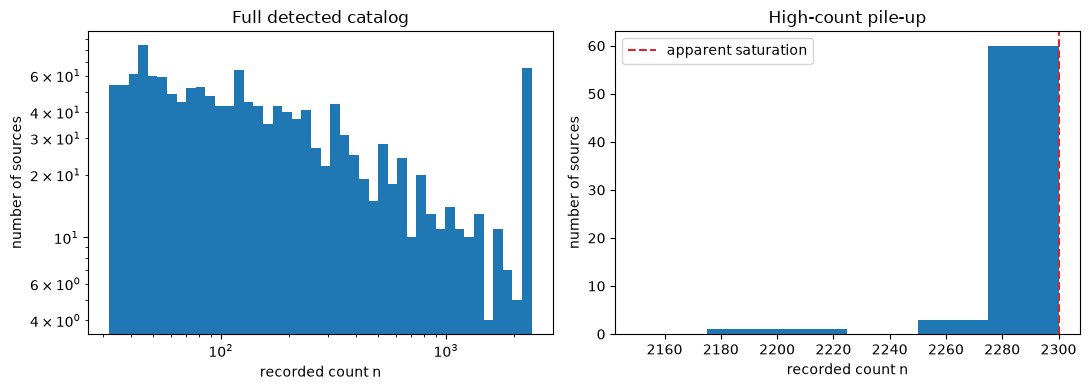

In [9]:
# Part 2: your work here
n = pd.read_csv(LAB+f'{NETID}.csv')['n_counts'].to_numpy()

fig,ax = plt.subplots(1,2,figsize=(11,4))

ax[0].hist(n,bins=np.logspace(np.log10(32),np.log10(2400),45))
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel('recorded count n')
ax[0].set_ylabel('number of sources')
ax[0].set_title('Full detected catalog')

ax[1].hist(n,bins=np.arange(2150,2325,25))
ax[1].axvline(2300,color='C3',ls='--',label='apparent saturation')
ax[1].set_xlabel('recorded count n')
ax[1].set_ylabel('number of sources')
ax[1].set_title('High-count pile-up')
ax[1].legend()

plt.tight_layout()
plt.show()

sources = 1500
detected minimum = 33
right-censored sources = 60
right-censored fraction = 4.0%


,fit,mu,mu_err,sigma,sigma_err,f_det
0,"naive, 2300 treated literally",-0.488803,0.032293,1.244403,0.022958,0.922089
1,"naive, right-censored",-0.470988,0.033581,1.291821,0.024635,0.916599
2,"detector corrected, 2300 literal",-1.419455,0.131538,1.791098,0.072010,0.684793
3,"detector corrected, right-censored",-1.794662,0.203262,2.047793,0.101667,0.594810


Effect of right-censoring, ignoring detector:
delta mu = 0.018
delta sigma = 0.047

Effect of right-censoring, including detector:
delta mu = -0.375
delta sigma = 0.257


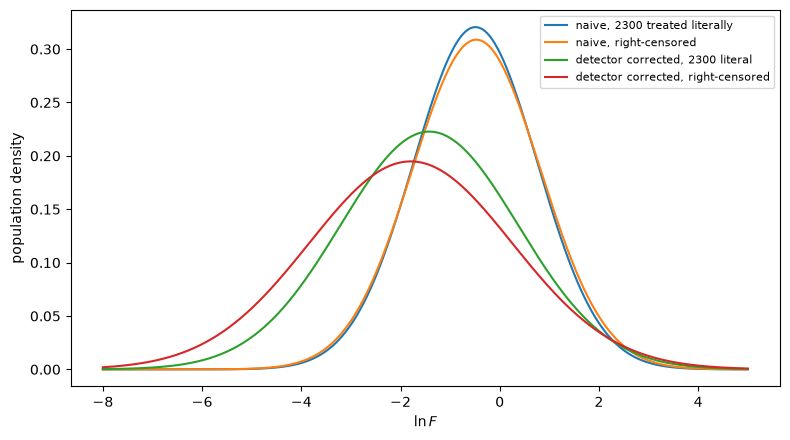

In [10]:
# Part 2: reusable likelihood with right-censoring at n = 2300

from scipy.special import logsumexp


nu,eps,n_th = 9.373,226.27,32
n_sat = 2300
sat = (n == n_sat)
Ndet = len(n)

print('sources =',Ndet)
print('detected minimum =',n.min())
print('right-censored sources =',sat.sum())
print('right-censored fraction = {:.1%}'.format(sat.mean()))

# Integration grid in x = ln(F)
lnF = np.arange(-14,8.0001,0.005)
dlnF = lnF[1]-lnF[0]
F = np.exp(lnF)
lam = eps*F+nu

# Cache count probabilities because these do not depend on mu or sigma
log_p_exact = stats.poisson.logpmf(n[:,None],lam[None,:])

# Recorded n = 2300 means the uncensored count was >= 2300
log_p_sat = stats.poisson.logsf(n_sat-1,lam)

# The survey retains a source when n > 32, meaning n >= 33
log_p_det = stats.poisson.logsf(n_th,lam)

def log_population(mu,sigma):
    """Log density of ln(F) under the population model."""
    return stats.norm.logpdf(lnF,mu,sigma)

def nll_counts(p,censored=True,selection=False):
    """
    Marginal negative log-likelihood.

    p = (mu, log_sigma)
    censored=True treats recorded 2300 as n >= 2300.
    selection=True conditions on inclusion in the detected catalog.
    """
    mu,log_sigma = p
    sigma = np.exp(log_sigma)

    if not (-14 < mu < 8 and 0.02 < sigma < 5):
        return np.inf

    log_pop = log_population(mu,sigma)

    # Exact-count likelihood integrated over latent ln(F)
    log_like_i = (
        logsumexp(log_p_exact+log_pop[None,:],axis=1)
        +np.log(dlnF)
    )

    # Replace the 60 exact-count terms with right-censored terms
    if censored:
        log_like_sat = (
            logsumexp(log_p_sat+log_pop)
            +np.log(dlnF)
        )
        log_like_i[sat] = log_like_sat

    log_like = log_like_i.sum()

    # Condition on detection: every retained source has n > 32
    if selection:
        log_fdet = (
            logsumexp(log_p_det+log_pop)
            +np.log(dlnF)
        )
        log_like -= Ndet*log_fdet

    return -log_like

def hessian(fun,p,h=1e-4):
    """Numerical Hessian of a two-parameter function."""
    p = np.asarray(p,float)
    H = np.zeros((len(p),len(p)))

    for i in range(len(p)):
        for j in range(len(p)):
            ei = np.zeros(len(p))
            ej = np.zeros(len(p))
            ei[i] = h
            ej[j] = h

            H[i,j] = (
                fun(p+ei+ej)-fun(p+ei-ej)
                -fun(p-ei+ej)+fun(p-ei-ej)
            )/(4*h**2)

    return H

def fit_counts(censored=True,selection=False,p0=(-1.0,0.0)):
    """Fit mu and sigma and return curvature uncertainties."""
    result = minimize(
        lambda p: nll_counts(
            p,
            censored=censored,
            selection=selection
        ),
        p0,
        method='Nelder-Mead',
        options=dict(
            maxiter=5000,
            xatol=1e-8,
            fatol=1e-8
        )
    )

    if not result.success:
        raise RuntimeError(result.message)

    H = hessian(
        lambda p: nll_counts(
            p,
            censored=censored,
            selection=selection
        ),
        result.x
    )

    cov = np.linalg.inv(H)

    mu,log_sigma = result.x
    sigma = np.exp(log_sigma)

    mu_err = np.sqrt(cov[0,0])
    sigma_err = sigma*np.sqrt(cov[1,1])

    log_pop = log_population(mu,sigma)
    fdet = np.exp(
        logsumexp(log_p_det+log_pop)+np.log(dlnF)
    )

    return dict(
        mu=mu,
        mu_err=mu_err,
        sigma=sigma,
        sigma_err=sigma_err,
        fdet=fdet,
        result=result
    )

# Four fits isolate the saturation and detector effects
fit_naive_literal = fit_counts(
    censored=False,
    selection=False
)

fit_naive_censored = fit_counts(
    censored=True,
    selection=False
)

fit_corrected_literal = fit_counts(
    censored=False,
    selection=True
)

fit_corrected_censored = fit_counts(
    censored=True,
    selection=True
)

fits = {
    'naive, 2300 treated literally':fit_naive_literal,
    'naive, right-censored':fit_naive_censored,
    'detector corrected, 2300 literal':fit_corrected_literal,
    'detector corrected, right-censored':fit_corrected_censored
}

rows = []

for name,fit in fits.items():
    rows.append([
        name,
        fit['mu'],
        fit['mu_err'],
        fit['sigma'],
        fit['sigma_err'],
        fit['fdet']
    ])

fit_table = pd.DataFrame(
    rows,
    columns=[
        'fit','mu','mu_err',
        'sigma','sigma_err','f_det'
    ]
)

display(fit_table)

# Directly show the effect of the saturation treatment
print('Effect of right-censoring, ignoring detector:')
print('delta mu = {:.3f}'.format(
    fit_naive_censored['mu']
    -fit_naive_literal['mu']
))
print('delta sigma = {:.3f}'.format(
    fit_naive_censored['sigma']
    -fit_naive_literal['sigma']
))

print('\nEffect of right-censoring, including detector:')
print('delta mu = {:.3f}'.format(
    fit_corrected_censored['mu']
    -fit_corrected_literal['mu']
))
print('delta sigma = {:.3f}'.format(
    fit_corrected_censored['sigma']
    -fit_corrected_literal['sigma']
))

# Visual comparison of the four fitted ln(F) populations
xx = np.linspace(-8,5,1000)

plt.figure(figsize=(8,4.5))

for name,fit in fits.items():
    plt.plot(
        xx,
        stats.norm.pdf(xx,fit['mu'],fit['sigma']),
        label=name
    )

plt.xlabel(r'$\ln F$')
plt.ylabel('population density')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

Looking through the data I can see that 4% of counts are piled up at a upper limit of n = 2300. The same way the prompt has a lower bound on counts it seems to have an upper bound where it assigns any points with n >= 2300 to simply 2300. There are 60 points piled on this upper bound which is about 4% of my data. To handel this I will treat these 60 points as right censored, P(n >= 2300 | F) rather than P(n = 2300 | F). Combining this effect with the faint end truncation at n <= 32 we can see that there is a significant impack on both the sigma and the mu when applying these effects. Accounting for right censuring always increased the detected sigma on ln(F) and increased mu when detector effects where not considered. The proper model including both effect including the right sensoring actually lowers mu because my model now accounts for undetected sources.

,F_over_F0,mean_count,gammainc,poisson_sf,absolute_difference
0,0.00,9.3730,1.588631e-09,1.588631e-09,0.0
1,0.03,16.1611,1.560936e-04,1.560936e-04,0.0
2,0.05,20.6865,7.565954e-03,7.565954e-03,0.0
3,0.10,32.0000,4.531714e-01,4.531714e-01,0.0
4,0.20,54.6270,9.993498e-01,9.993498e-01,0.0
5,1.00,235.6430,1.000000e+00,1.000000e+00,0.0


largest absolute difference = 0.000e+00
50% detection flux = 0.1029 F0
mean count at 50% detection = 32.667 counts
p_det at this flux = 0.500000


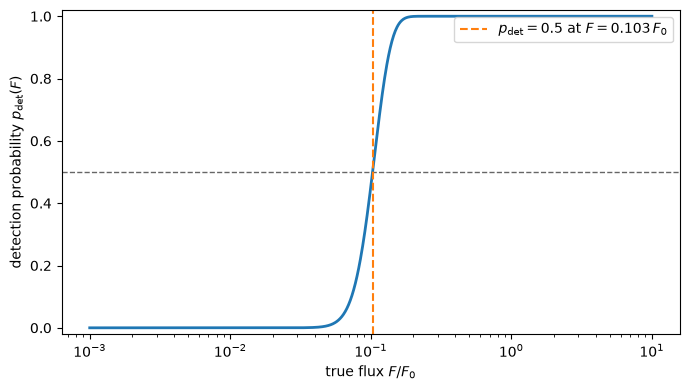

In [11]:
# Part 2.2: sampling distribution and detection probability

from scipy.special import gammainc
from scipy.optimize import brentq

nu,eps,n_th = 9.373,226.27,32

# Sampling distribution:
# n | F ~ Poisson(eps*F + nu)
def poisson_mean(F):
    return eps*F+nu

# Detection means n > 32, equivalently n >= 33
def p_det(F):
    lam = poisson_mean(F)
    return gammainc(n_th+1,lam)

# Check the closed form against scipy.stats.poisson.sf
F_check = np.array([0.00,0.03,0.05,0.10,0.20,1.00])
lam_check = poisson_mean(F_check)

p_gamma = p_det(F_check)
p_scipy = stats.poisson.sf(n_th,lam_check)

check_table = pd.DataFrame({
    'F_over_F0':F_check,
    'mean_count':lam_check,
    'gammainc':p_gamma,
    'poisson_sf':p_scipy,
    'absolute_difference':np.abs(p_gamma-p_scipy)
})

display(check_table)

print('largest absolute difference = {:.3e}'.format(
    check_table['absolute_difference'].max()
))

# Solve p_det(F) = 0.5
F_half = brentq(
    lambda F: p_det(F)-0.5,
    0.0,
    1.0
)

print('50% detection flux = {:.4f} F0'.format(F_half))
print('mean count at 50% detection = {:.3f} counts'.format(
    poisson_mean(F_half)
))
print('p_det at this flux = {:.6f}'.format(p_det(F_half)))

# Detection-probability plot
F_plot = np.logspace(-3,1,1000)

plt.figure(figsize=(7,4))
plt.plot(F_plot,p_det(F_plot),lw=2)
plt.axhline(0.5,color='0.4',ls='--',lw=1)
plt.axvline(
    F_half,
    color='C1',
    ls='--',
    label=fr'$p_{{\rm det}}=0.5$ at $F={F_half:.3f}\,F_0$'
)


plt.xscale('log')
plt.xlabel(r'true flux $F/F_0$')
plt.ylabel(r'detection probability $p_{\rm det}(F)$')
plt.ylim(-0.02,1.02)
plt.legend()
plt.tight_layout()
plt.show()

# Numerical verification
assert np.allclose(p_gamma,p_scipy,rtol=1e-12,atol=1e-14)
assert np.isclose(p_det(F_half),0.5,rtol=1e-10)

A source is detected half of the time at a true flux of $0.103F_0$

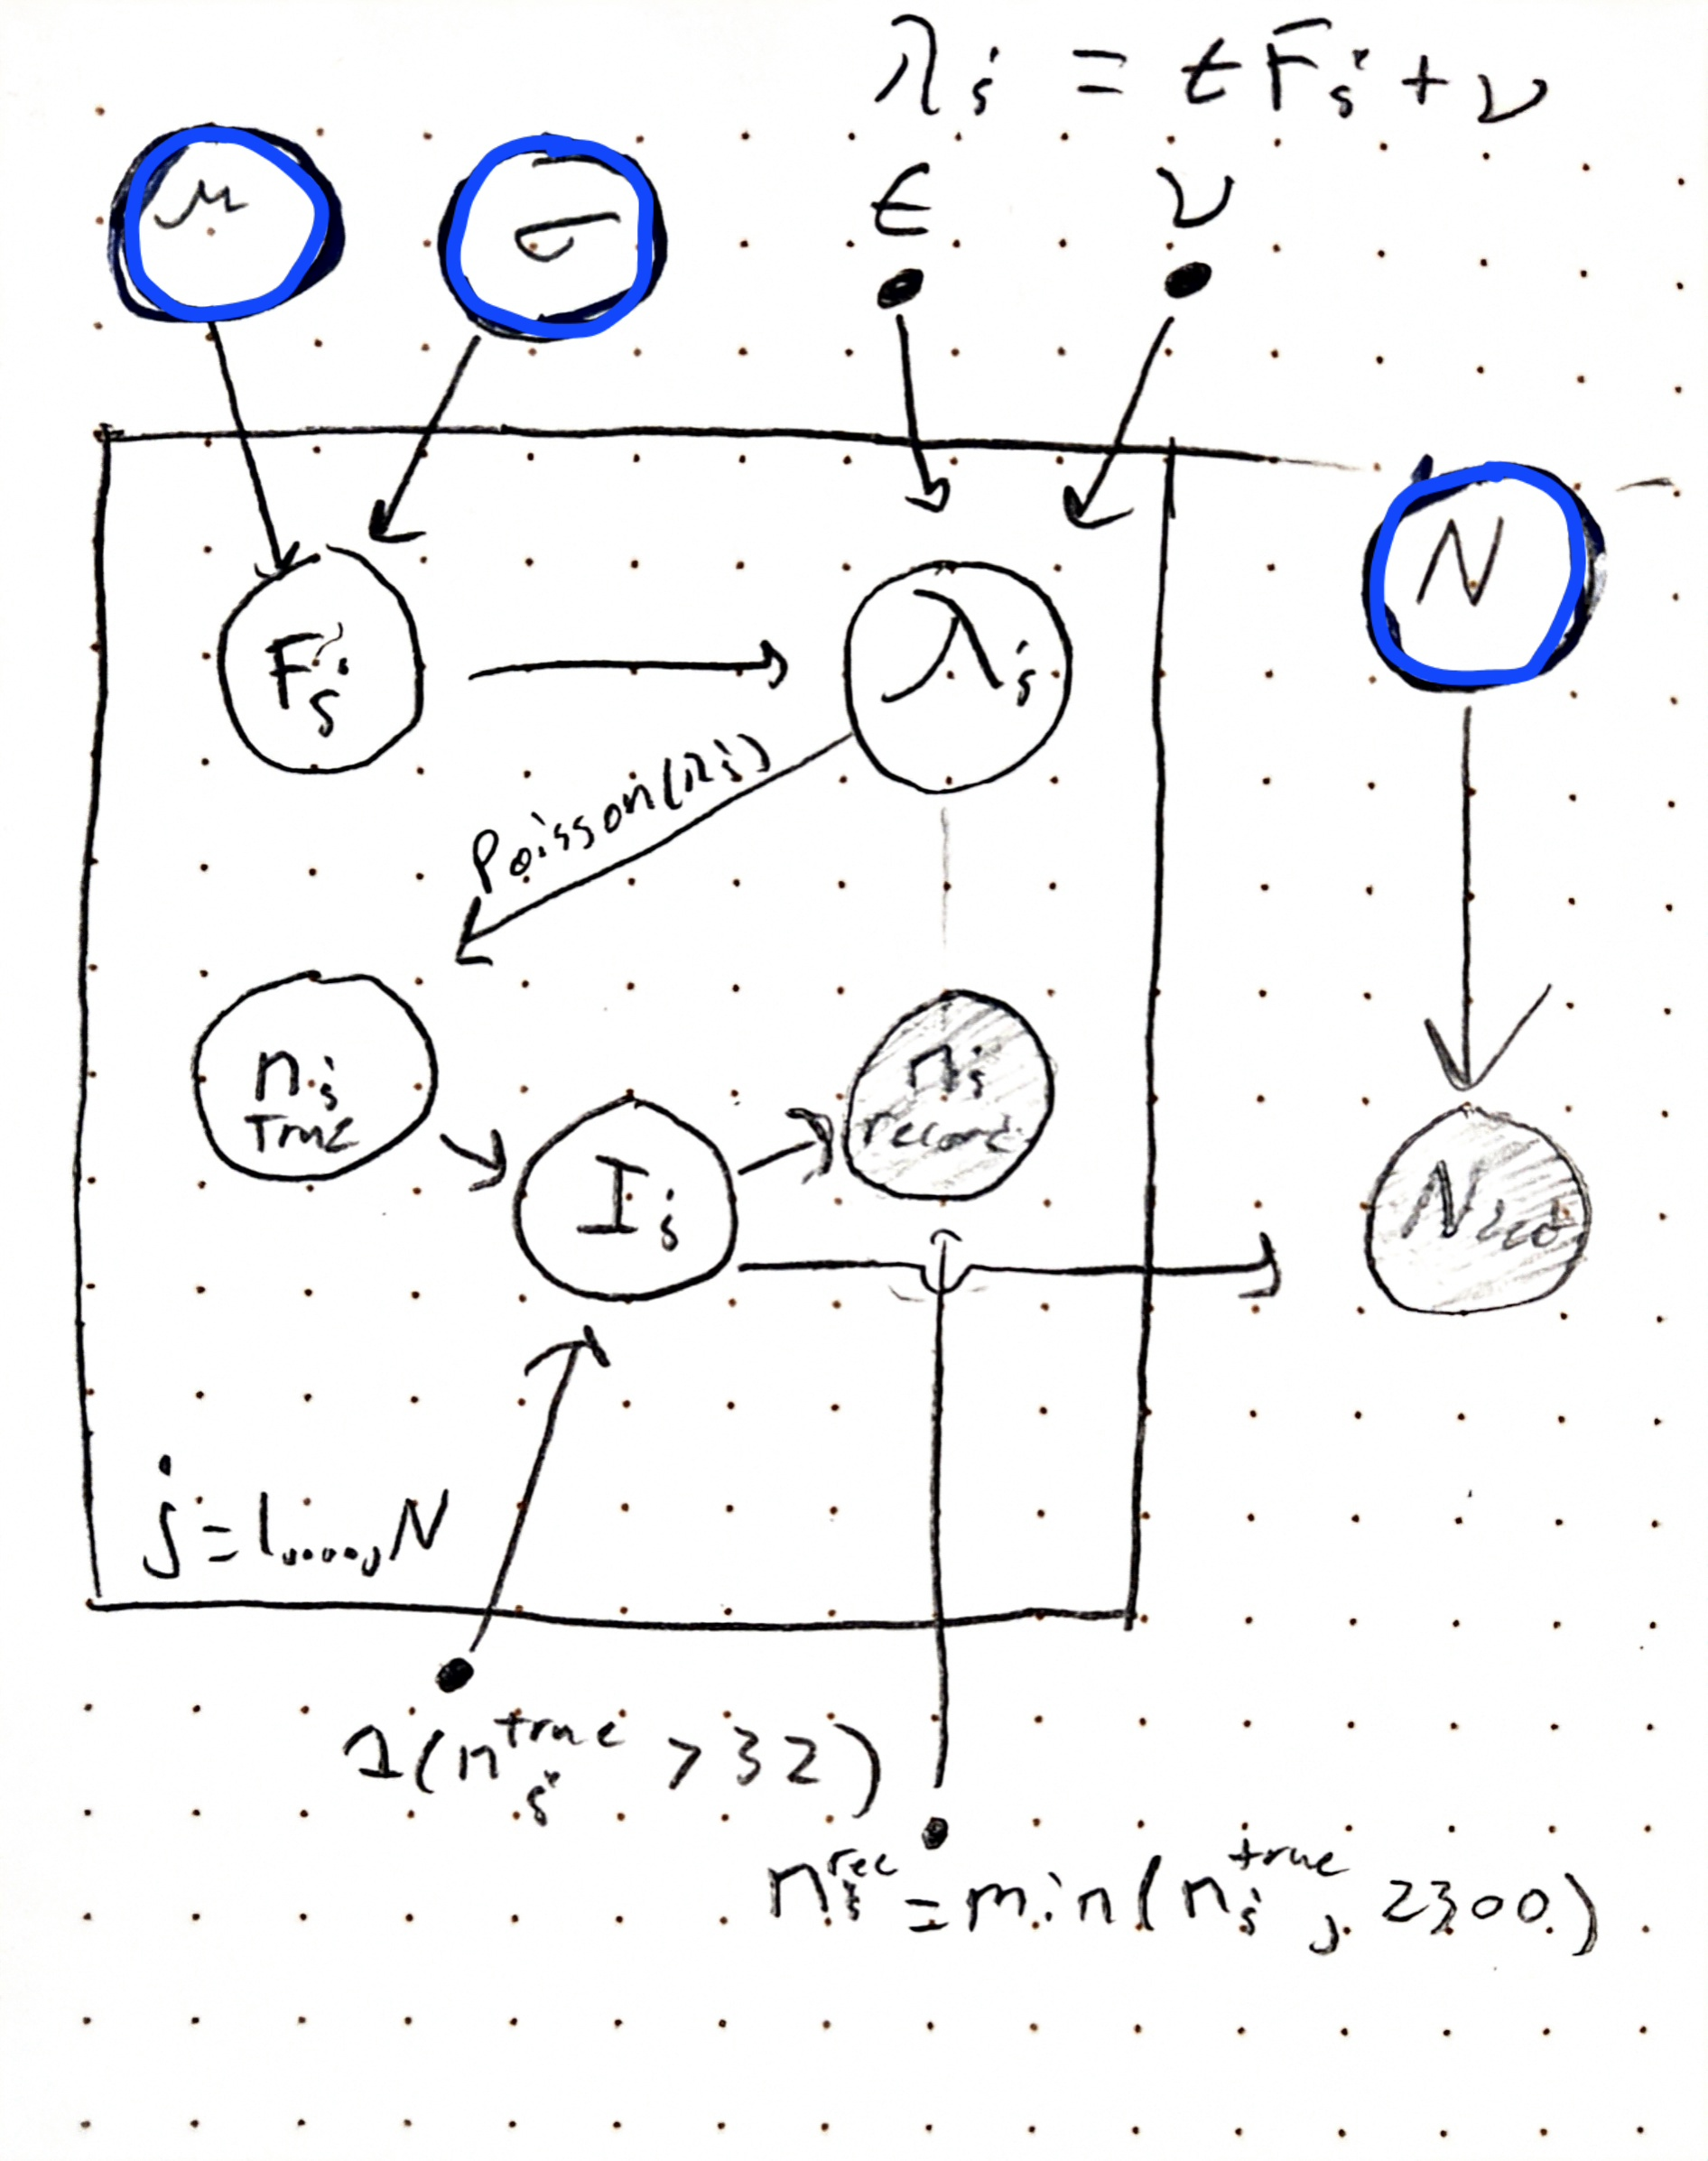


In [12]:
# Part 2.4: grid integral and naive maximum-likelihood fit
# Right-censored at 2300 counts, but not yet corrected for n > 32 selection

from scipy.special import logsumexp
from scipy.optimize import minimize

n = pd.read_csv(LAB+f'{NETID}.csv')['n_counts'].to_numpy()

nu,eps = 9.373,226.27
n_sat = 2300
saturated = (n == n_sat)

# Grid in ln(F), following the prompt
lnF = np.arange(-14,8.0001,0.005)
dlnF = lnF[1]-lnF[0]

F = np.exp(lnF)
lam = eps*F+nu

# p(n_i | F) for every source and every ln(F) grid point
log_p_count = stats.poisson.logpmf(
    n[:,None],
    lam[None,:]
)

# For recorded n = 2300, use P(n_true >= 2300 | F)
log_p_saturated = stats.poisson.logsf(
    n_sat-1,
    lam
)

def log_likelihood_naive(p):
    mu,log_sigma = p
    sigma = np.exp(log_sigma)

    if not (-14 < mu < 8 and 0.02 < sigma < 5):
        return -np.inf

    # Population density in ln(F)
    log_population = stats.norm.logpdf(
        lnF,
        loc=mu,
        scale=sigma
    )

    # Integral for ordinary exact-count observations
    log_probability = (
        logsumexp(
            log_p_count+log_population[None,:],
            axis=1
        )
        +np.log(dlnF)
    )

    # Replace the 2300-count terms with censored integrals
    log_probability_saturated = (
        logsumexp(
            log_p_saturated+log_population
        )
        +np.log(dlnF)
    )

    log_probability[saturated] = log_probability_saturated

    return np.sum(log_probability)

# Optimize in mu and log(sigma), ensuring sigma stays positive
fit_naive = minimize(
    lambda p: -log_likelihood_naive(p),
    x0=np.array([-0.5,np.log(1.3)]),
    method='Nelder-Mead',
    options=dict(
        maxiter=5000,
        xatol=1e-8,
        fatol=1e-8
    )
)

if not fit_naive.success:
    raise RuntimeError(fit_naive.message)

mu_naive = fit_naive.x[0]
sigma_naive = np.exp(fit_naive.x[1])

# Curvature uncertainties for the naive fit

def hessian(fun,p,h=1e-4):
    p = np.asarray(p,float)
    H = np.zeros((len(p),len(p)))

    for i in range(len(p)):
        for j in range(len(p)):
            ei = np.zeros(len(p))
            ej = np.zeros(len(p))

            ei[i] = h
            ej[j] = h

            H[i,j] = (
                fun(p+ei+ej)
                -fun(p+ei-ej)
                -fun(p-ei+ej)
                +fun(p-ei-ej)
            )/(4*h**2)

    return H

H_naive = hessian(
    lambda p: -log_likelihood_naive(p),
    fit_naive.x
)

cov_naive = np.linalg.inv(H_naive)

mu_naive_err = np.sqrt(cov_naive[0,0])

# The fit samples log(sigma), so propagate its error to sigma
log_sigma_naive_err = np.sqrt(cov_naive[1,1])
sigma_naive_err = sigma_naive*log_sigma_naive_err

print(
    'Naive fit: mu = {:.3f} +/- {:.3f}'.format(
        mu_naive,
        mu_naive_err
    )
)

print(
    'Naive fit: sigma = {:.3f} +/- {:.3f}'.format(
        sigma_naive,
        sigma_naive_err
    )
)

assert np.all(np.linalg.eigvalsh(H_naive) > 0)

Naive fit: mu = -0.471 +/- 0.034
Naive fit: sigma = 1.292 +/- 0.025


In [13]:
# Part 2.4: naive and detector-corrected fits with right-censoring

from scipy.special import logsumexp
from scipy.optimize import minimize

# Data and survey settings
n = pd.read_csv(LAB+f'{NETID}.csv')['n_counts'].to_numpy()

nu,eps,n_th,n_sat = 9.373,226.27,32,2300
Ndet = len(n)
saturated = (n == n_sat)

# Build ALL grid-dependent arrays together
lnF = np.arange(-14,8.0001,0.005)
dlnF = lnF[1]-lnF[0]
F = np.exp(lnF)
lam = eps*F+nu

# Exact-count likelihood on the same ln(F) grid
log_p_count = stats.poisson.logpmf(
    n[:,None],
    lam[None,:]
)

# Recorded 2300 means true count >= 2300
log_p_saturated = stats.poisson.logsf(
    n_sat-1,
    lam
)

# Detection means n > 32
log_p_det = stats.poisson.logsf(
    n_th,
    lam
)

# Shape checks prevent stale-grid broadcasting errors
assert log_p_count.shape == (Ndet,len(lnF))
assert log_p_saturated.shape == lnF.shape
assert log_p_det.shape == lnF.shape

def log_likelihood_naive(p):
    mu,log_sigma = p
    sigma = np.exp(log_sigma)

    if not (-14 < mu < 8 and 0.02 < sigma < 5):
        return -np.inf

    log_population = stats.norm.logpdf(
        lnF,
        loc=mu,
        scale=sigma
    )

    # Integrate p(n_i|F)p(lnF|mu,sigma) over ln(F)
    log_probability = (
        logsumexp(
            log_p_count+log_population[None,:],
            axis=1
        )
        +np.log(dlnF)
    )

    # Replace exact n=2300 probabilities with P(n_true >= 2300)
    log_probability_saturated = (
        logsumexp(
            log_p_saturated+log_population
        )
        +np.log(dlnF)
    )

    log_probability[saturated] = log_probability_saturated

    return np.sum(log_probability)

def log_fdet(p):
    mu,log_sigma = p
    sigma = np.exp(log_sigma)

    if not (-14 < mu < 8 and 0.02 < sigma < 5):
        return -np.inf

    log_population = stats.norm.logpdf(
        lnF,
        loc=mu,
        scale=sigma
    )

    return (
        logsumexp(log_p_det+log_population)
        +np.log(dlnF)
    )

def log_likelihood_corrected(p):
    log_like = log_likelihood_naive(p)
    log_detected_fraction = log_fdet(p)

    if not np.isfinite(log_like):
        return -np.inf

    if not np.isfinite(log_detected_fraction):
        return -np.inf

    return log_like-Ndet*log_detected_fraction

def hessian(fun,p,h=1e-4):
    p = np.asarray(p,float)
    H = np.zeros((len(p),len(p)))

    for i in range(len(p)):
        for j in range(len(p)):
            ei = np.zeros(len(p))
            ej = np.zeros(len(p))

            ei[i] = h
            ej[j] = h

            H[i,j] = (
                fun(p+ei+ej)
                -fun(p+ei-ej)
                -fun(p-ei+ej)
                +fun(p-ei-ej)
            )/(4*h**2)

    return H

def fit_likelihood(loglike,starts):
    fits = []

    for start in starts:
        result = minimize(
            lambda p: -loglike(p),
            x0=np.asarray(start),
            method='Nelder-Mead',
            options=dict(
                maxiter=10000,
                xatol=1e-8,
                fatol=1e-8
            )
        )

        if result.success and np.isfinite(result.fun):
            fits.append(result)

    if len(fits) == 0:
        raise RuntimeError('All optimization attempts failed.')

    result = min(fits,key=lambda r:r.fun)

    H = hessian(
        lambda p: -loglike(p),
        result.x,
        h=1e-4
    )

    if np.any(np.linalg.eigvalsh(H) <= 0):
        raise RuntimeError('Hessian is not positive definite.')

    cov = np.linalg.inv(H)

    mu,log_sigma = result.x
    sigma = np.exp(log_sigma)

    mu_error = np.sqrt(cov[0,0])
    sigma_error = sigma*np.sqrt(cov[1,1])

    return dict(
        result=result,
        mu=mu,
        mu_error=mu_error,
        sigma=sigma,
        sigma_error=sigma_error,
        H=H,
        cov=cov
    )

# Fit naive likelihood from multiple starts
naive_starts = [
    [-0.5,np.log(1.3)],
    [-1.0,np.log(1.5)],
    [0.0,np.log(1.0)]
]

naive = fit_likelihood(
    log_likelihood_naive,
    naive_starts
)

# Use the naive maximum plus wider starts for corrected likelihood
corrected_starts = [
    naive['result'].x,
    [-1.0,np.log(1.5)],
    [-2.0,np.log(2.0)],
    [-3.0,np.log(2.5)]
]

corrected = fit_likelihood(
    log_likelihood_corrected,
    corrected_starts
)

# Detection fraction and inferred source counts
fdet = np.exp(log_fdet(corrected['result'].x))
Ntotal = Ndet/fdet
Nmissed = Ntotal-Ndet

# Clear output table
results_24 = pd.DataFrame({
    'fit':['naive','detector corrected'],
    'mu':[naive['mu'],corrected['mu']],
    'mu uncertainty':[naive['mu_error'],corrected['mu_error']],
    'sigma':[naive['sigma'],corrected['sigma']],
    'sigma uncertainty':[
        naive['sigma_error'],
        corrected['sigma_error']
    ]
}).set_index('fit')

print('PART 2.4 RESULTS')
print('Integration-grid spacing in ln(F) =',dlnF)
print('Detected sources =',Ndet)
print('Right-censored sources =',saturated.sum())
display(results_24.round(3))

print(
    'Naive fit: '
    'mu = {:.3f} +/- {:.3f}, '
    'sigma = {:.3f} +/- {:.3f}'.format(
        naive['mu'],
        naive['mu_error'],
        naive['sigma'],
        naive['sigma_error']
    )
)

print(
    'Detector-corrected fit: '
    'mu = {:.3f} +/- {:.3f}, '
    'sigma = {:.3f} +/- {:.3f}'.format(
        corrected['mu'],
        corrected['mu_error'],
        corrected['sigma'],
        corrected['sigma_error']
    )
)

print('f_det = {:.4f}'.format(fdet))
print('estimated total sources = {:.0f}'.format(Ntotal))
print('estimated sources missed = {:.0f}'.format(Nmissed))

# Final consistency checks
assert Ndet == 1500
assert saturated.sum() == 60
assert n.min() == 33
assert n.max() == 2300
assert naive['result'].success
assert corrected['result'].success
assert 0 < fdet < 1
assert Ntotal >= Ndet

PART 2.4 RESULTS
Integration-grid spacing in ln(F) = 0.005000000000000782
Detected sources = 1500
Right-censored sources = 60


,mu,mu uncertainty,sigma,sigma uncertainty
fit,,,,
naive,-0.471,0.034,1.292,0.025
detector corrected,-1.795,0.203,2.048,0.102


Naive fit: mu = -0.471 +/- 0.034, sigma = 1.292 +/- 0.025
Detector-corrected fit: mu = -1.795 +/- 0.203, sigma = 2.048 +/- 0.102
f_det = 0.5948
estimated total sources = 2522
estimated sources missed = 1022


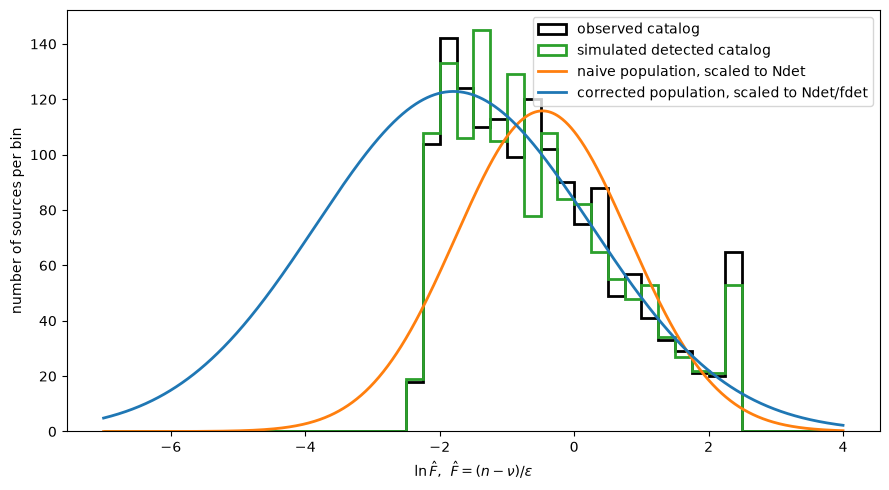

Observed detected sources = 1500
Corrected detected fraction = 0.5948
Simulated underlying sources = 2522
Simulated detected sources = 1475
Simulated recorded at 2300 = 51
Expected detected number = 1500


In [14]:
# Part 2.5: observed ln(Fhat), fitted populations, and simulated survey

rng = np.random.default_rng(2026)

mu_naive = naive['mu']
sigma_naive = naive['sigma']

mu_corrected = corrected['mu']
sigma_corrected = corrected['sigma']

Ndet = len(n)
Ntotal = int(np.round(Ndet/fdet))

# Flux estimates from the recorded catalog counts
Fhat = (n-nu)/eps
lnFhat = np.log(Fhat)

# Simulate the full underlying population from the corrected fit
lnF_true_sim = rng.normal(
    mu_corrected,
    sigma_corrected,
    Ntotal
)

F_true_sim = np.exp(lnF_true_sim)

# Draw uncensored Poisson counts
n_true_sim = rng.poisson(
    eps*F_true_sim+nu
)

# Apply the survey's actual faint-end detector
detected_sim = (n_true_sim > n_th)

# Apply the bright-end recording ceiling after detection
n_recorded_sim = np.minimum(
    n_true_sim[detected_sim],
    n_sat
)

Fhat_sim = (n_recorded_sim-nu)/eps
lnFhat_sim = np.log(Fhat_sim)

# Common histogram bins
bins = np.linspace(
    min(lnFhat.min(),lnFhat_sim.min(),-7),
    max(lnFhat.max(),lnFhat_sim.max(),4),
    45
)

bin_width = bins[1]-bins[0]
x = np.linspace(bins[0],bins[-1],1000)

# Curves expressed as expected number of sources per histogram bin
naive_curve = (
    Ndet
    *stats.norm.pdf(x,mu_naive,sigma_naive)
    *bin_width
)

corrected_curve = (
    Ntotal
    *stats.norm.pdf(x,mu_corrected,sigma_corrected)
    *bin_width
)

plt.figure(figsize=(9,5))

plt.hist(
    lnFhat,
    bins=bins,
    histtype='step',
    lw=2,
    color='k',
    label='observed catalog'
)

plt.hist(
    lnFhat_sim,
    bins=bins,
    histtype='step',
    lw=2,
    color='C2',
    label='simulated detected catalog'
)

plt.plot(
    x,
    naive_curve,
    color='C1',
    lw=2,
    label='naive population, scaled to Ndet'
)

plt.plot(
    x,
    corrected_curve,
    color='C0',
    lw=2,
    label='corrected population, scaled to Ndet/fdet'
)

plt.xlabel(r'$\ln \hat F$,  $\hat F=(n-\nu)/\epsilon$')
plt.ylabel('number of sources per bin')
plt.legend()
plt.tight_layout()
plt.show()

print('Observed detected sources =',Ndet)
print('Corrected detected fraction = {:.4f}'.format(fdet))
print('Simulated underlying sources =',Ntotal)
print('Simulated detected sources =',detected_sim.sum())
print('Simulated recorded at 2300 =',
      np.sum(n_recorded_sim == n_sat))

print(
    'Expected detected number = {:.0f}'.format(
        Ntotal*fdet
    )
)

# Basic checks
assert np.all(Fhat > 0)
assert np.all(Fhat_sim > 0)
assert np.all(n_recorded_sim > n_th)
assert np.all(n_recorded_sim <= n_sat)

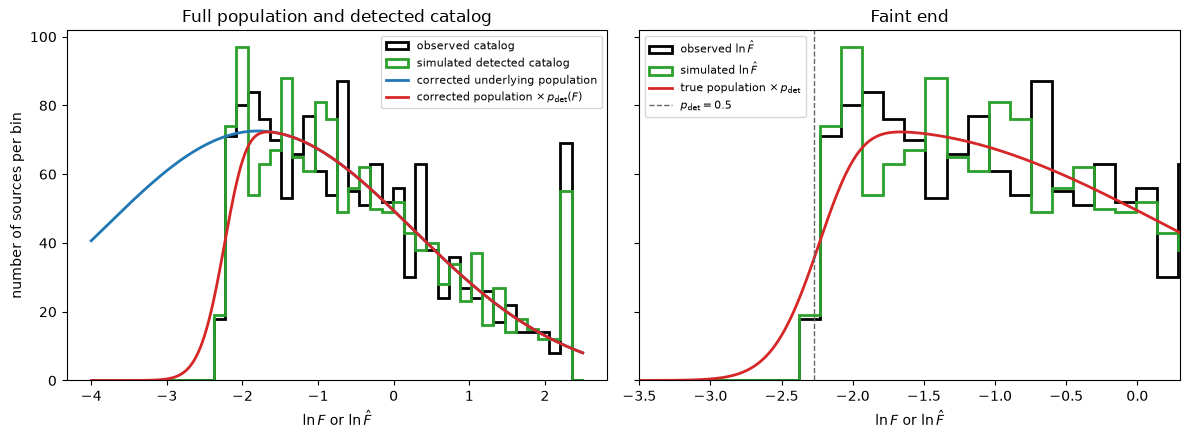

50% detection flux = 0.1029 F0
ln of 50% detection flux = -2.274
corrected detected fraction = 0.5948
corrected total population = 2522
detected sources represented over plotted range = 39643


In [15]:
# Part 2.5: corrected population times p_det(F), compared at the faint end

Ndet = len(n)
Ntotal = Ndet/fdet

mu_corrected = corrected['mu']
sigma_corrected = corrected['sigma']

# Measured catalog flux estimator
Fhat = (n-nu)/eps
lnFhat = np.log(Fhat)

# Plot range and common bins in ln(F)
bins = np.linspace(-4.0,2.5,45)
bin_width = bins[1]-bins[0]
x = np.linspace(bins[0],bins[-1],1200)
F_curve = np.exp(x)

# Corrected underlying population in expected sources per bin
corrected_population = (
    Ntotal
    *stats.norm.pdf(x,mu_corrected,sigma_corrected)
    *bin_width
)

# Detection probability for each true flux
pdet_curve = stats.poisson.sf(
    n_th,
    eps*F_curve+nu
)

# Corrected true-flux population after passing through the detector
corrected_detected = corrected_population*pdet_curve

fig,ax = plt.subplots(
    1,2,
    figsize=(12,4.5),
    sharey=True
)

# Full comparison
ax[0].hist(
    lnFhat,
    bins=bins,
    histtype='step',
    color='k',
    lw=2,
    label='observed catalog'
)

ax[0].hist(
    lnFhat_sim,
    bins=bins,
    histtype='step',
    color='C2',
    lw=2,
    label='simulated detected catalog'
)

ax[0].plot(
    x,
    corrected_population,
    color='C0',
    lw=2,
    label='corrected underlying population'
)

ax[0].plot(
    x,
    corrected_detected,
    color='C3',
    lw=2,
    label=r'corrected population $\times\,p_{\rm det}(F)$'
)

ax[0].set_xlabel(r'$\ln F$ or $\ln\hat F$')
ax[0].set_ylabel('number of sources per bin')
ax[0].set_title('Full population and detected catalog')
ax[0].legend(fontsize=8)

# Faint-end comparison
ax[1].hist(
    lnFhat,
    bins=bins,
    histtype='step',
    color='k',
    lw=2,
    label=r'observed $\ln\hat F$'
)

ax[1].hist(
    lnFhat_sim,
    bins=bins,
    histtype='step',
    color='C2',
    lw=2,
    label=r'simulated $\ln\hat F$'
)

ax[1].plot(
    x,
    corrected_detected,
    color='C3',
    lw=2,
    label=r'true population $\times\,p_{\rm det}$'
)

# Approximate flux corresponding to the count threshold
F_threshold = (n_th-nu)/eps
lnF_threshold = np.log(F_threshold)

# Flux detected half the time, from Part 2.2
F_half = brentq(
    lambda F: stats.poisson.sf(
        n_th,
        eps*F+nu
    )-0.5,
    0.0,
    1.0
)

ax[1].axvline(
    np.log(F_half),
    color='0.4',
    ls='--',
    lw=1,
    label=r'$p_{\rm det}=0.5$'
)

ax[1].set_xlim(-3.5,0.3)
ax[1].set_xlabel(r'$\ln F$ or $\ln\hat F$')
ax[1].set_title('Faint end')
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print('50% detection flux = {:.4f} F0'.format(F_half))
print('ln of 50% detection flux = {:.3f}'.format(np.log(F_half)))
print('corrected detected fraction = {:.4f}'.format(fdet))
print('corrected total population = {:.0f}'.format(Ntotal))

# Numerical normalization check
expected_detected = np.sum(
    corrected_detected
)

print(
    'detected sources represented over plotted range = {:.0f}'.format(
        expected_detected
    )
)

**ANSWER (the two fits, f_det and the number missed, then the explanation):**

I used the cuverature of the likelyhood to estimate the parameter uncertainty for this data. I found an $f_{det}$ of .59 estimating that ~1022 sources were missed by this survey.

My simulated catalog closesly matched my observed catalog in the histogram but it does not exactly match the underlysing detected population. The reason for this discrepancy is that the population curve is reprisenting the true flux values of the sources, the histograhm is the measured flux. These values differ by the scatter in the catalogue which causes the difference on the faint end. Ignoring the detector positivly biased mu while decreasing sigma. Ignoring the detector effects also lowers the error in these parameters. The reason why this effect biases both parameters is because it changes the shape of the assumed population from a positively skewed gaussian to a gaussian with only half being observed, shifting both the distributions center and spread.

## Part 3: A supernova in two dimensions (25%)

This one is real. The Carnegie Supernova Project (CSP-I) observed nearby Type Ia supernovae in six optical bands, from $u$ (364 nm) to $i$ (761 nm). Look up your supernova and your held-out band in `08/data/csp_assignments.csv`. Your light curve is `08/data/csp/<SN>.csv`, with columns `mjd`, `band`, `wavelength_A` (the band's effective wavelength), `flux_ujy` and `flux_err_ujy` (flux density in μJy), and the magnitudes they came from. The header gives the redshift and the date of maximum light in $B$. Data: Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0; credit the Carnegie Supernova Project).

Work in rest-frame phase, $(\mathrm{MJD} - T_{B\,\rm max})/(1+z)$, from $-10$ to $+40$ days, and divide every flux by the peak $B$ flux. Note that `V0`, `V1` and `V` are three versions of the same filter (within 32 Å) - treat them as one band, $V$.

A supernova's light curves in neighboring bands look alike, so a Gaussian process in **two** inputs, phase and wavelength, can learn all six at once and predict a band it never saw.

1. Plot every band against phase.
2. Fit a GP to the flux as a function of (phase, wavelength) using every band **except** your held-out one, with wavelength in microns (so both inputs are numbers of order 1-50). Use a kernel with its own length scale in phase and in wavelength (an anisotropic squared-exponential) times a fitted amplitude, each point's own measurement error, and a small white-noise term that you also fit. Fit the hyperparameters by maximizing the marginal likelihood (as in Lab 07), from more than one start. `sklearn`'s `GaussianProcessRegressor` (with `alpha` set to the squared errors, `normalize_y=False`, and `ConstantKernel` times `RBF` plus `WhiteKernel`) or your own Cholesky code from Lab 07 are both fine. Report the two length scales, and comment on what each means physically for a supernova.
3. Predict your held-out band at its epochs, with the GP's $1\sigma$ band, and plot it over the data. Report the rms residual as a fraction of the peak, and the fraction of held-out points within $1\sigma$ (add the GP's variance and the measurement variance). Does the GP's error bar look reasonable?
4. Now hold out $u$ instead, and report the same two numbers. Why is this so much harder? Think particularly about what the kernel assumes, and how far $u$ is from the other bands compared with your first held-out band.

In [16]:
# Part 3: your work here
asg = pd.read_csv(LAB + 'csp_assignments.csv')
SN, HOLD = asg.loc[asg.netid == NETID, ['sn', 'holdout_band']].iloc[0]
path = LAB + f'csp/{SN}.csv'
hdr = [l for l in open(path) if l.startswith('#')]          # the header lines: source, license, redshift, date of B maximum
z = float([l for l in hdr if 'z_helio' in l][0].split(':')[-1])
tmax = float([l for l in hdr if 'B-max MJD' in l][0].split(':')[1].split('+/-')[0])
d = pd.read_csv(path, comment='#')
d['band'] = d['band'].replace({'V0': 'V', 'V1': 'V'})   # V0, V1 and V are the same filter - treat them as one band
print(f'{SN}: z = {z}, B maximum at MJD {tmax}, {len(d)} points; held-out band: {HOLD}')

SN2004ef: z = 0.031, B maximum at MJD 53263.77, 261 points; held-out band: g


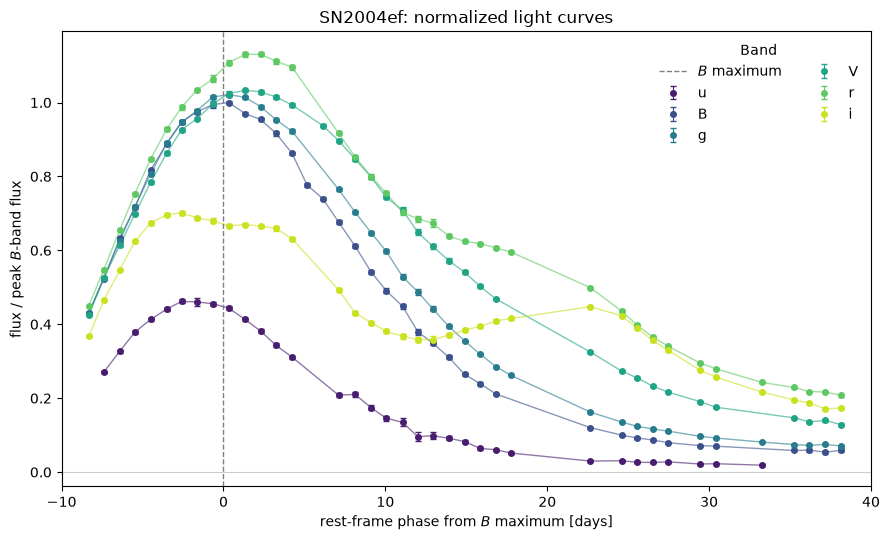

Supernova: SN2004ef
Redshift = 0.0310
B maximum MJD = 53263.77
Peak B flux = 614.30 uJy
Points plotted = 222
Bands plotted = u, B, g, V, r, i


In [17]:
# Part 3.1: plot every band against rest-frame phase

d = pd.read_csv(path,comment='#')

# Combine the three versions of the V filter
d['band'] = d['band'].replace({
    'V0':'V',
    'V1':'V',
    'Ve':'V'
})

# Rest-frame phase relative to B-band maximum
d['phase'] = (d['mjd']-tmax)/(1+z)

# Keep the phase range requested in the prompt
d = d.loc[
    (d['phase'] >= -10)&
    (d['phase'] <= 40)
].copy()

# Normalize by the observed peak B-band flux in this phase range
B = d.loc[d['band'] == 'B'].copy()

if len(B) == 0:
    raise ValueError('No B-band observations are available.')

peak_B_flux = B['flux_ujy'].max()

d['flux_norm'] = d['flux_ujy']/peak_B_flux
d['flux_err_norm'] = d['flux_err_ujy']/peak_B_flux

# Order bands by effective wavelength
band_order = (
    d.groupby('band')['wavelength_A']
    .median()
    .sort_values()
    .index
    .tolist()
)

fig,ax = plt.subplots(figsize=(9,5.5))

colors = plt.cm.viridis(
    np.linspace(0.08,0.92,len(band_order))
)

for band,color in zip(band_order,colors):
    db = d.loc[d['band'] == band].sort_values('phase')

    ax.errorbar(
        db['phase'],
        db['flux_norm'],
        yerr=db['flux_err_norm'],
        fmt='o',
        ms=4,
        capsize=2,
        elinewidth=0.8,
        color=color,
        label=band
    )

    ax.plot(
        db['phase'],
        db['flux_norm'],
        lw=1,
        alpha=0.6,
        color=color
    )

ax.axvline(
    0,
    color='0.5',
    ls='--',
    lw=1,
    label=r'$B$ maximum'
)

ax.axhline(
    0,
    color='0.8',
    lw=0.8
)

ax.set_xlim(-10,40)
ax.set_xlabel(r'rest-frame phase from $B$ maximum [days]')
ax.set_ylabel(r'flux / peak $B$-band flux')
ax.set_title(
    '{}: normalized light curves'.format(SN)
)

ax.legend(
    title='Band',
    ncol=2,
    frameon=False
)

plt.tight_layout()
plt.show()

print('Supernova:',SN)
print('Redshift = {:.4f}'.format(z))
print('B maximum MJD = {:.2f}'.format(tmax))
print('Peak B flux = {:.2f} uJy'.format(peak_B_flux))
print('Points plotted =',len(d))
print('Bands plotted =',', '.join(band_order))



In [25]:
#3.2
# Part 3.2: fit a 2D GP to normalized flux using every band except g

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel

# Use all valid observations except the held-out g band
train = d.loc[
    d['band'].astype(str).str.lower().ne('g'),
    ['phase', 'wavelength_A', 'flux_norm', 'flux_err_norm', 'band']
].dropna().copy()

if train.empty:
    raise ValueError('No valid training data remain after excluding band g.')

if np.any(train['flux_err_norm'].to_numpy() <= 0):
    raise ValueError('All flux measurement errors must be positive.')

# Two GP inputs: rest-frame phase [days] and wavelength [microns]
X_train = np.column_stack([
    train['phase'].to_numpy(dtype=float),
    train['wavelength_A'].to_numpy(dtype=float) / 1e4
])

y_train = train['flux_norm'].to_numpy(dtype=float)
yerr_train = train['flux_err_norm'].to_numpy(dtype=float)

# Standardize the target explicitly so the measurement errors are placed
# on the same scale as the GP target.
gp_y_mean = np.mean(y_train)
gp_y_scale = np.std(y_train)

if not np.isfinite(gp_y_scale) or gp_y_scale <= 0:
    raise ValueError('The training fluxes have zero or invalid scatter.')

y_fit = (y_train - gp_y_mean) / gp_y_scale
yerr_fit = yerr_train / gp_y_scale

# Fitted amplitude times an anisotropic squared-exponential kernel:
# separate length scales for phase and wavelength, plus fitted white noise.
kernel = (
    ConstantKernel(
        constant_value=1.0,
        constant_value_bounds=(1e-4, 1e3)
    )
    * RBF(
        length_scale=[10.0, 0.10],
        length_scale_bounds=[
            (0.1, 100.0),    # phase length scale [days]
            (1e-3, 10.0)     # wavelength length scale [microns]
        ]
    )
    + WhiteKernel(
        noise_level=1e-4,
        noise_level_bounds=(1e-10, 1e-1)
    )
)

gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=yerr_fit**2,        # each point's own measurement-error variance
    optimizer='fmin_l_bfgs_b',
    n_restarts_optimizer=20,  # maximize marginal likelihood from multiple starts
    normalize_y=False,        # target and errors were standardized together above
    random_state=457
)

gp.fit(X_train, y_fit)

# Extract fitted hyperparameters
amplitude_std = np.sqrt(gp.kernel_.k1.k1.constant_value)
phase_scale, wavelength_scale = gp.kernel_.k1.k2.length_scale
white_noise_std = np.sqrt(gp.kernel_.k2.noise_level)

# Convert amplitude and extra white noise back to normalized-flux units
amplitude_flux = amplitude_std * gp_y_scale
white_noise_flux = white_noise_std * gp_y_scale

log_marginal_likelihood = gp.log_marginal_likelihood(gp.kernel_.theta)

print('Supernova:', SN)
print('Training bands:', ', '.join(sorted(train['band'].unique())))
print('Held-out band: g')
print('Training points:', len(train))
print('Optimized kernel:', gp.kernel_)
print(f'Fitted GP amplitude = {amplitude_flux:.6f} normalized flux')
print(f'Phase length scale = {phase_scale:.6f} days')
print(f'Wavelength length scale = {wavelength_scale:.6f} microns')
print(f'Additional white-noise standard deviation = {white_noise_flux:.6f} normalized flux')
print(f'Maximum log marginal likelihood = {log_marginal_likelihood:.6f}')

Supernova: SN2004ef
Training bands: B, V, i, r, u
Held-out band: g
Training points: 184
Optimized kernel: 0.891**2 * RBF(length_scale=[6, 0.111]) + WhiteKernel(noise_level=1.9e-05)
Fitted GP amplitude = 0.275233 normalized flux
Phase length scale = 5.996223 days
Wavelength length scale = 0.111033 microns
Additional white-noise standard deviation = 0.001347 normalized flux
Maximum log marginal likelihood = 295.374201


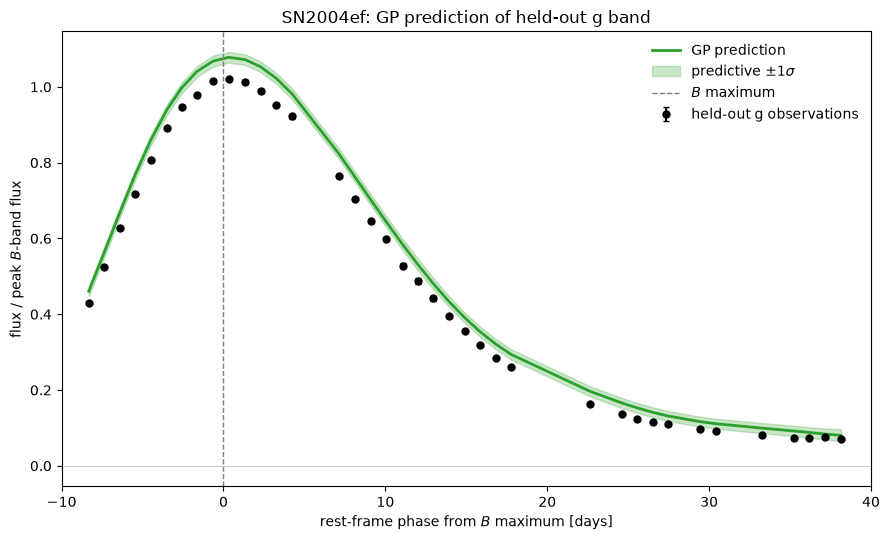

Held-out g-band points = 38
RMS residual as a fraction of peak B-band flux = 0.0429
Points within predictive 1 sigma = 2 of 38 (0.053)
Median predictive 1-sigma width = 0.0138
Mean signed residual = -0.0397
Fitted kernel: 0.891**2 * RBF(length_scale=[6, 0.111]) + WhiteKernel(noise_level=1.9e-05)


In [26]:
# Part 3.3: predict held-out g-band measurements at their observed epochs

import numpy as np
import matplotlib.pyplot as plt

g_data = (
    d.loc[
        d['band'].astype(str).str.lower().eq('g'),
        ['phase', 'wavelength_A', 'flux_norm', 'flux_err_norm']
    ]
    .dropna()
    .sort_values('phase')
    .copy()
)

if g_data.empty:
    raise ValueError('No valid g-band observations are available.')

X_g = np.column_stack([
    g_data['phase'].to_numpy(dtype=float),
    g_data['wavelength_A'].to_numpy(dtype=float) / 1e4
])

g_phase = g_data['phase'].to_numpy(dtype=float)
g_observed = g_data['flux_norm'].to_numpy(dtype=float)
g_observed_err = g_data['flux_err_norm'].to_numpy(dtype=float)

# Predict using the standardized GP from Part 3.2
g_pred_scaled, g_gp_std_scaled = gp.predict(X_g, return_std=True)

# Return to normalized-flux units
g_pred = gp_y_mean + gp_y_scale * g_pred_scaled
g_gp_std = gp_y_scale * g_gp_std_scaled

# gp.predict includes uncertainty from the fitted GP kernel and WhiteKernel.
# Add the held-out observations' quoted measurement errors for comparison
# against the actual measured g-band fluxes.
g_total_std = np.sqrt(g_gp_std**2 + g_observed_err**2)

residuals = g_observed - g_pred
rms_residual_fraction = np.sqrt(np.mean(residuals**2))

within_1sigma = np.abs(residuals) <= g_total_std
fraction_within_1sigma = within_1sigma.mean()

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.errorbar(
    g_phase,
    g_observed,
    yerr=g_observed_err,
    fmt='o',
    ms=5,
    capsize=2,
    color='black',
    label='held-out g observations'
)

ax.plot(
    g_phase,
    g_pred,
    color='tab:green',
    lw=2,
    label='GP prediction'
)

ax.fill_between(
    g_phase,
    g_pred - g_total_std,
    g_pred + g_total_std,
    color='tab:green',
    alpha=0.25,
    label=r'predictive $\pm 1\sigma$'
)

ax.axvline(0, color='0.5', ls='--', lw=1, label=r'$B$ maximum')
ax.axhline(0, color='0.8', lw=0.8)

ax.set_xlim(-10, 40)
ax.set_xlabel(r'rest-frame phase from $B$ maximum [days]')
ax.set_ylabel(r'flux / peak $B$-band flux')
ax.set_title(f'{SN}: GP prediction of held-out g band')
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

print(f'Held-out g-band points = {len(g_observed)}')
print(
    'RMS residual as a fraction of peak B-band flux = '
    f'{rms_residual_fraction:.4f}'
)
print(
    f'Points within predictive 1 sigma = '
    f'{within_1sigma.sum()} of {len(within_1sigma)} '
    f'({fraction_within_1sigma:.3f})'
)
print(f'Median predictive 1-sigma width = {np.median(g_total_std):.4f}')
print(f'Mean signed residual = {np.mean(residuals):+.4f}')
print('Fitted kernel:', gp.kernel_)

It looks like my GP model does a reasonable job predicting the mean rest phase from B but it considerably off when predicting the flux per epoch. Notably the error bars seem to be significantly undereprisented corresponding to an overconfident fit

C:\Users\austi\anaconda3\envs\astr457\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


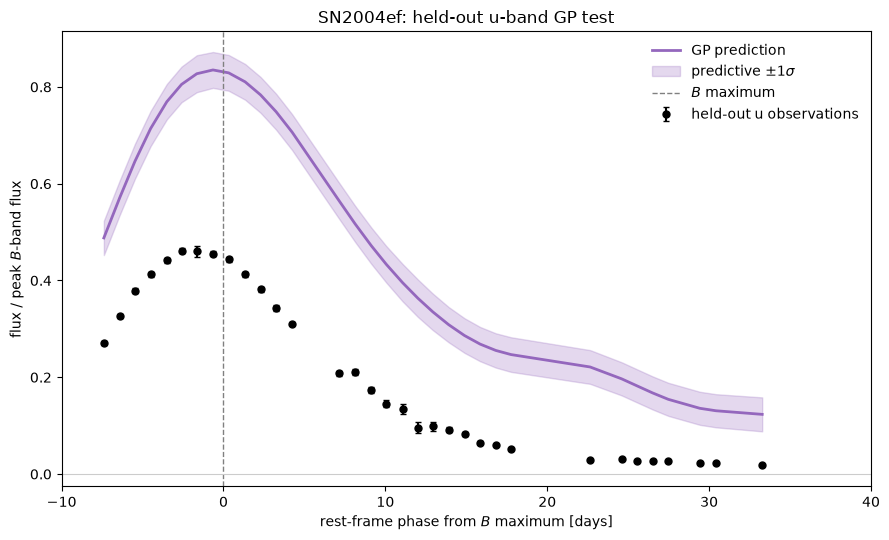

Held-out band: u
Training bands: B, V, g, i, r
Held-out u-band points = 33
RMS residual as a fraction of peak B-band flux = 0.2762
Points within predictive 1 sigma = 0 of 33 (0.000)
Median predictive 1-sigma width = 0.0364
Mean signed residual = -0.2598
Optimized kernel: 0.775**2 * RBF(length_scale=[5.7, 0.13]) + WhiteKernel(noise_level=1e-10)


In [27]:
# Held-out test: refit the GP without u, then predict u at its observed epochs

import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel

TEST_BAND = 'u'

# ------------------------------------------------------------------
# 1. Split the data into non-u training data and held-out u data
# ------------------------------------------------------------------
train_u_test = (
    d.loc[
        d['band'].astype(str).str.lower().ne(TEST_BAND),
        ['phase', 'wavelength_A', 'flux_norm', 'flux_err_norm', 'band']
    ]
    .dropna()
    .copy()
)

heldout_u = (
    d.loc[
        d['band'].astype(str).str.lower().eq(TEST_BAND),
        ['phase', 'wavelength_A', 'flux_norm', 'flux_err_norm', 'band']
    ]
    .dropna()
    .sort_values('phase')
    .copy()
)

if train_u_test.empty:
    raise ValueError('No valid training points remain after excluding u.')

if heldout_u.empty:
    raise ValueError('No valid u-band observations are available.')

if np.any(train_u_test['flux_err_norm'].to_numpy() <= 0):
    raise ValueError('All training measurement errors must be positive.')

# Phase is in days; convert wavelength from Angstroms to microns
X_train_u = np.column_stack([
    train_u_test['phase'].to_numpy(dtype=float),
    train_u_test['wavelength_A'].to_numpy(dtype=float) / 1e4
])

y_train_u = train_u_test['flux_norm'].to_numpy(dtype=float)
yerr_train_u = train_u_test['flux_err_norm'].to_numpy(dtype=float)

# ------------------------------------------------------------------
# 2. Standardize flux and measurement errors together
# ------------------------------------------------------------------
u_test_y_mean = np.mean(y_train_u)
u_test_y_scale = np.std(y_train_u)

if not np.isfinite(u_test_y_scale) or u_test_y_scale <= 0:
    raise ValueError('Training fluxes have zero or invalid scatter.')

y_train_u_scaled = (y_train_u - u_test_y_mean) / u_test_y_scale
yerr_train_u_scaled = yerr_train_u / u_test_y_scale

# ------------------------------------------------------------------
# 3. Fit the GP using all bands except u
# ------------------------------------------------------------------
kernel_u_test = (
    ConstantKernel(
        constant_value=1.0,
        constant_value_bounds=(1e-4, 1e3)
    )
    * RBF(
        length_scale=[10.0, 0.10],
        length_scale_bounds=[
            (0.1, 100.0),   # phase length scale in days
            (1e-3, 10.0)    # wavelength length scale in microns
        ]
    )
    + WhiteKernel(
        noise_level=1e-4,
        noise_level_bounds=(1e-10, 1e-1)
    )
)

gp_u_test = GaussianProcessRegressor(
    kernel=kernel_u_test,
    alpha=yerr_train_u_scaled**2,
    optimizer='fmin_l_bfgs_b',
    n_restarts_optimizer=20,
    normalize_y=False,
    random_state=457
)

gp_u_test.fit(X_train_u, y_train_u_scaled)

# ------------------------------------------------------------------
# 4. Predict u at its actual observed epochs
# ------------------------------------------------------------------
X_u = np.column_stack([
    heldout_u['phase'].to_numpy(dtype=float),
    heldout_u['wavelength_A'].to_numpy(dtype=float) / 1e4
])

u_pred_scaled, u_gp_std_scaled = gp_u_test.predict(
    X_u,
    return_std=True
)

# Convert predictions back to normalized-flux units
u_pred = u_test_y_mean + u_test_y_scale * u_pred_scaled
u_gp_std = u_test_y_scale * u_gp_std_scaled

u_phase = heldout_u['phase'].to_numpy(dtype=float)
u_observed = heldout_u['flux_norm'].to_numpy(dtype=float)
u_observed_err = heldout_u['flux_err_norm'].to_numpy(dtype=float)

# Include each held-out observation's quoted measurement uncertainty
u_total_std = np.sqrt(u_gp_std**2 + u_observed_err**2)

# ------------------------------------------------------------------
# 5. Evaluate the held-out predictions
# ------------------------------------------------------------------
u_residuals = u_observed - u_pred
u_rms_residual = np.sqrt(np.mean(u_residuals**2))

u_within_1sigma = np.abs(u_residuals) <= u_total_std
u_fraction_within_1sigma = np.mean(u_within_1sigma)

# ------------------------------------------------------------------
# 6. Plot the result
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.errorbar(
    u_phase,
    u_observed,
    yerr=u_observed_err,
    fmt='o',
    ms=5,
    capsize=2,
    color='black',
    label='held-out u observations'
)

ax.plot(
    u_phase,
    u_pred,
    color='tab:purple',
    lw=2,
    label='GP prediction'
)

ax.fill_between(
    u_phase,
    u_pred - u_total_std,
    u_pred + u_total_std,
    color='tab:purple',
    alpha=0.25,
    label=r'predictive $\pm 1\sigma$'
)

ax.axvline(0, color='0.5', ls='--', lw=1, label=r'$B$ maximum')
ax.axhline(0, color='0.8', lw=0.8)
ax.set_xlim(-10, 40)
ax.set_xlabel(r'rest-frame phase from $B$ maximum [days]')
ax.set_ylabel(r'flux / peak $B$-band flux')
ax.set_title(f'{SN}: held-out u-band GP test')
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 7. Report concise diagnostics
# ------------------------------------------------------------------
print('Held-out band: u')
print(
    'Training bands:',
    ', '.join(sorted(train_u_test['band'].astype(str).unique()))
)
print(f'Held-out u-band points = {len(u_observed)}')
print(
    'RMS residual as a fraction of peak B-band flux = '
    f'{u_rms_residual:.4f}'
)
print(
    f'Points within predictive 1 sigma = '
    f'{u_within_1sigma.sum()} of {len(u_within_1sigma)} '
    f'({u_fraction_within_1sigma:.3f})'
)
print(f'Median predictive 1-sigma width = {np.median(u_total_std):.4f}')
print(f'Mean signed residual = {np.mean(u_residuals):+.4f}')
print('Optimized kernel:', gp_u_test.kernel_)

**ANSWER (length scales, the two held-out tests, then why u is harder):**
The pase length scall depicts how rapidly the supernova light curve changed with time. The wavelength scale is how quickly the lightcurve changed between filters

u is significantly harder to predict because it has a shape and amplitude that deviates from the other bands. That being said even with band g appearing as a pretty average lightcurve none of my GP models were able to retain 68% of the datapoints in 1$\sigma$ error bars. The data is too different for the conditioned models to do a good job at predicting any one band. The kernel makes optimistic assumptions that lead to underestimated errors. The kernel assumes that flux is a stationary smooth varying function of phase and wavelength with one global correlation length in each dimention. These assumptions do not account for the significant variation between bands found in the data.

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 1 and Part 2 numbers, and what failure would have looked like for each. Part 1.3 is already one. For Part 2, one check to consider is to simulate a catalog yourself with a $\mu$ and $\sigma$ you choose, through the same detector, run both fits on it, and see whether the corrected fit gets back what you put in and the naive one doesn't. One catalog isn't enough - comment on how many you'd need.

**AI-USE APPENDIX:**

I used a custom agent in microsoft copilot to help me with this lab. Most of the code was written by that agent. I also used AI to help me with some of the graphs after I had already sketched it to confirm my work. I initially thought that my results for part 3 were incorrect and spent a significant amount of time trying to get a code output that covered more of the data. Aven after switching to a different model I got the same results so I decided to accept the,

**REFLECTION:**

The AI could be writing incorrect code for the GP model in part 3 and I would not know. I tried comparing the results from two different AIs (co-pilot and GPT-5.6) and they both came to the same conclusion. The code in this lab finally breached my knowledge and the time contraints have kept me from going through and learning the process as much as I would like. If the GP model in part 3 is wrong then my analysis is also wrong

**VERIFICATION PLAN:**

For part 1 testing my data against simulations was a pretty clear verification to show that the latent model performs better and without attenuation when compared to the midterm model. 

For part 2 my graph showing the effects of adding in the detector effects an right censoring were a very good chack to make sure that the effects I saw later were what I expected. 

For the part 2 simulated catalog check I will follow the procedure outlined in the prompt. Failure would be if the naive fit perfroms better than the one considering detector effects. I would 100 catalogs for a reasonable bias check but for the sake of time this will only be a one catalouge spot check

In [32]:
%%time
# Fast Part 2 verification using one simulated catalog.
# This is a spot check, not a full bias or coverage calibration.

rng = np.random.default_rng(457)

# Inject the detector-corrected population fit as the known truth
mu_true = fit_corrected_censored['mu']
sigma_true = fit_corrected_censored['sigma']

# Simulate the inferred total underlying population
Ntrue = int(np.round(Ndet / fit_corrected_censored['fdet']))

# ------------------------------------------------------------------
# 1. Simulate the population and pass it through the same detector
# ------------------------------------------------------------------
lnF_true = rng.normal(
    loc=mu_true,
    scale=sigma_true,
    size=Ntrue
)

F_true = np.exp(lnF_true)
lam_true = eps * F_true + nu

# Uncensored Poisson detector counts
n_raw = rng.poisson(lam_true)

# Survey retains sources only when n > n_th
detected = (n_raw > n_th)

# Saturated counts are recorded as n_sat
n_sim = np.minimum(n_raw[detected], n_sat)

Ndet_sim = len(n_sim)
sat_sim = (n_sim == n_sat)

# ------------------------------------------------------------------
# 2. Use a coarser grid for this verification only
# ------------------------------------------------------------------
lnF_sim = np.arange(-14, 8.0001, 0.02)
dlnF_sim = lnF_sim[1] - lnF_sim[0]
F_sim = np.exp(lnF_sim)
lam_sim = eps * F_sim + nu

# Aggregate repeated unsaturated counts
unique_n_sim, multiplicity_sim = np.unique(
    n_sim[~sat_sim],
    return_counts=True
)

# Critical speed improvement:
# compute all Poisson probabilities once, not during optimization
log_p_exact_sim = stats.poisson.logpmf(
    unique_n_sim[:, None],
    lam_sim[None, :]
)

log_p_sat_sim = stats.poisson.logsf(
    n_sat - 1,
    lam_sim
)

log_p_det_sim = stats.poisson.logsf(
    n_th,
    lam_sim
)


def nll_verification(p, selection):
    """
    Likelihood for the one simulated catalog.

    Both fits handle saturation correctly.
    selection=True also corrects for the detection threshold.
    """
    mu, log_sigma = p
    sigma = np.exp(log_sigma)

    if not (-14 < mu < 8 and 0.02 < sigma < 5):
        return np.inf

    log_pop = stats.norm.logpdf(
        lnF_sim,
        mu,
        sigma
    )

    # Marginal likelihood for each unique unsaturated count
    log_like_unique = (
        logsumexp(
            log_p_exact_sim + log_pop[None, :],
            axis=1
        )
        + np.log(dlnF_sim)
    )

    log_like = np.sum(
        multiplicity_sim * log_like_unique
    )

    # Right-censored saturated observations
    if sat_sim.sum() > 0:
        log_like_sat = (
            logsumexp(log_p_sat_sim + log_pop)
            + np.log(dlnF_sim)
        )

        log_like += sat_sim.sum() * log_like_sat

    # Condition on inclusion in the detected catalog
    if selection:
        log_fdet = (
            logsumexp(log_p_det_sim + log_pop)
            + np.log(dlnF_sim)
        )

        log_like -= Ndet_sim * log_fdet

    return -log_like


# Start both optimizations at the injected truth
p0 = np.array([
    mu_true,
    np.log(sigma_true)
])

# Naive fit: handles saturation but ignores the detection threshold
result_naive_sim = minimize(
    lambda p: nll_verification(
        p,
        selection=False
    ),
    p0,
    method='L-BFGS-B',
    bounds=[
        (-13.99, 7.99),
        (np.log(0.021), np.log(4.99))
    ]
)

# Corrected fit: handles both saturation and detector selection
result_corrected_sim = minimize(
    lambda p: nll_verification(
        p,
        selection=True
    ),
    p0,
    method='L-BFGS-B',
    bounds=[
        (-13.99, 7.99),
        (np.log(0.021), np.log(4.99))
    ]
)

if not result_naive_sim.success:
    raise RuntimeError(
        'Naive fit failed: ' + result_naive_sim.message
    )

if not result_corrected_sim.success:
    raise RuntimeError(
        'Corrected fit failed: '
        + result_corrected_sim.message
    )

mu_naive_sim = result_naive_sim.x[0]
sigma_naive_sim = np.exp(result_naive_sim.x[1])

mu_corrected_sim = result_corrected_sim.x[0]
sigma_corrected_sim = np.exp(
    result_corrected_sim.x[1]
)

# Distances from the injected parameter pair
naive_error = np.sqrt(
    (mu_naive_sim - mu_true)**2
    + (sigma_naive_sim - sigma_true)**2
)

corrected_error = np.sqrt(
    (mu_corrected_sim - mu_true)**2
    + (sigma_corrected_sim - sigma_true)**2
)

print('SIMULATED-CATALOG SPOT CHECK')
print('Underlying simulated sources =', Ntrue)
print('Detected simulated sources =', Ndet_sim)
print(
    'Simulated detected fraction = {:.4f}'.format(
        detected.mean()
    )
)
print('Simulated saturated sources =', sat_sim.sum())

print('\nINJECTED TRUTH')
print('mu = {:.4f}'.format(mu_true))
print('sigma = {:.4f}'.format(sigma_true))

print('\nDETECTOR-CORRECTED FIT')
print('mu = {:.4f}'.format(mu_corrected_sim))
print('sigma = {:.4f}'.format(sigma_corrected_sim))
print(
    'distance from injected values = {:.4f}'.format(
        corrected_error
    )
)

print('\nNAIVE FIT')
print('mu = {:.4f}'.format(mu_naive_sim))
print('sigma = {:.4f}'.format(sigma_naive_sim))
print(
    'distance from injected values = {:.4f}'.format(
        naive_error
    )
)

if corrected_error < naive_error:
    print(
        '\nPASS: in this simulated catalog, the corrected fit '
        'is closer to the injected parameters than the naive fit.'
    )
else:
    print(
        '\nThis realization did not place the corrected fit closer. '
        'One catalog can fluctuate, so this alone does not show '
        'that the correction is biased.'
    )

SIMULATED-CATALOG SPOT CHECK
Underlying simulated sources = 2522
Detected simulated sources = 1510
Simulated detected fraction = 0.5987
Simulated saturated sources = 60

INJECTED TRUTH
mu = -1.7947
sigma = 2.0478

DETECTOR-CORRECTED FIT
mu = -1.8891
sigma = 2.0913
distance from injected values = 0.1039

NAIVE FIT
mu = -0.4762
sigma = 1.2989
distance from injected values = 1.5163

PASS: in this simulated catalog, the corrected fit is closer to the injected parameters than the naive fit.
CPU times: total: 797 ms
Wall time: 839 ms


This code passes the verification, where the naive fit fails to retain the true values the detector corrected fit retains the truth